<a href="https://colab.research.google.com/github/MrSiwan0909/silent-diabetes/blob/main/silent_diabetes.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Silent Diabetes: a no-blood-test screening tool

**Track:** AI + Health. Veritas AI International High School Hackathon 2026

**The idea:** about 64% of adults with diabetes in the UAE don't know they have it (IDF Diabetes Atlas estimate, [UAE page](https://diabetesatlas.org/data-by-location/country/united-arab-emirates/)). A pharmacist or a mall health-booth volunteer could ask about 10 simple questions (no blood test) and send higher-risk people to a doctor for an **HbA1c** blood test.

**This notebook:** loads the data, builds two baselines (including the American Diabetes Association's risk test), trains two models, picks a screening threshold, checks fairness, explains predictions, and saves the model for the app.

> This project is a prototype and is not medical advice.

## Summary (1-minute read)

**The problem:** about 64% of adults with diabetes in the UAE don't know they have it (IDF Diabetes Atlas estimate, [UAE page](https://diabetesatlas.org/data-by-location/country/united-arab-emirates/)). We built a one-minute, no-blood-test screening tool that a pharmacist can use to decide who should get an HbA1c blood test.

**Headline results on the held-out test set** (50,736 US adults, 7,069 with diabetes; the test set was used once, after all choices were made):

| | ADA checklist (5 of 7 questions, score ≥ 5) | Our model (logistic regression, 11 questions) | App version (age-group thresholds) |
|---|---|---|---|
| Diabetics caught (recall) | 81.2% | **84.9%** | **88.3%** |
| Diabetics missed | 1,331 | **1,065** | **829** |
| Healthy people sent for a test (false alarms) | 18,450 | **16,145** | 20,066 |
| Share of people flagged | 47.7% | **43.7%** | 51.8% |
| ROC-AUC (ranking quality, 0.5 = coin flip) | 0.757 | **0.815** | 0.815 (same model) |

**Three takeaways:**
1. **Our model beats the ADA's paper checklist on both counts:** 266 fewer diabetics missed *and* 2,305 fewer unnecessary referrals. Part of the gain comes from using more questions (Section 8).
2. **The fairness check found a real problem:** the model missed about half of diabetics under 40 (recall 48.4%). Lower thresholds for younger ages raised that to 88.0%, at a cost of about 17 extra blood tests per extra diabetic caught (Section 11). The app uses this fairer version.
3. **Questions can narrow down who needs a blood test, but they can't replace it.** Missed diabetics tend to look healthy (often young or lean), and the data is from US adults in 2015, so the tool needs UAE data with blood tests before real use (Sections 13-14).

> This project is a prototype and is not medical advice.


## 0. Setup: install and import packages

Google Colab already has pandas, scikit-learn and matplotlib. We only need to install:
- `ucimlrepo`: downloads datasets from the UCI Machine Learning Repository
- `gradio`: builds the simple web app at the end

In [1]:
# Install the two packages Colab doesn't have (-q = quiet, less text)
!pip install -q ucimlrepo gradio

In [2]:
import pandas as pd               # tables of data
import numpy as np                # maths on arrays of numbers
import matplotlib.pyplot as plt   # charts

# One fixed 'random seed' so we get the same results every time we run the notebook
RANDOM_SEED = 42

print('Packages loaded.')

Packages loaded.


## 1. Load the data

**Dataset:** CDC Diabetes Health Indicators. These are answers from the 2015 BRFSS phone survey of **253,680 US adults**. Each row is one person.

We download it fresh every time (it is **not** stored in our GitHub repo). If the `ucimlrepo` package fails, we read the same CSV file directly from the UCI website instead.

In [3]:
try:
    from ucimlrepo import fetch_ucirepo
    cdc = fetch_ucirepo(id=891)
    # cdc.data.features = the answers, cdc.data.targets = diabetes yes/no
    df = pd.concat([cdc.data.features, cdc.data.targets], axis=1)
    variable_info = cdc.variables   # official description of every column
    print('Loaded with ucimlrepo.')
except Exception as error:
    print('ucimlrepo failed:', error)
    print('Reading the CSV straight from the UCI website instead...')
    df = pd.read_csv('https://archive.ics.uci.edu/static/public/891/data.csv')
    df = df.drop(columns=['ID'])   # ID is just a row number, not useful
    variable_info = None

print('Rows (people):', len(df))
print('Columns:', len(df.columns))
df.head()

Loaded with ucimlrepo.
Rows (people): 253680
Columns: 22


,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,Veggies,...,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income,Diabetes_binary
0,1,1,1,40,1,0,0,0,0,1,...,0,5,18,15,1,0,9,4,3,0
1,0,0,0,25,1,0,0,1,0,0,...,1,3,0,0,0,0,7,6,1,0
2,1,1,1,28,0,0,0,0,1,0,...,1,5,30,30,1,0,9,4,8,0
3,1,0,1,27,0,0,0,1,1,1,...,0,2,0,0,0,0,11,3,6,0
4,1,1,1,24,0,0,0,1,1,1,...,0,2,3,0,0,0,11,5,4,0


### 1a. Choose only the questions a pharmacist can ask

The dataset has 21 questions. We keep only the ones you can answer **without a lab test** and that are quick to ask at a counter:

| Column | Question we would ask | Codes in the data |
|---|---|---|
| `Age` | How old are you? | **Groups, not years:** 1 = 18-24, 2 = 25-29, ... 5-year steps ... 12 = 75-79, 13 = 80+ |
| `Sex` | Sex | 0 = female, 1 = male |
| `BMI` | Height and weight (we calculate BMI) | a number, e.g. 27 |
| `HighBP` | Has a doctor ever told you that you have high blood pressure? | 0 = no, 1 = yes |
| `HighChol` | ...high cholesterol? | 0 = no, 1 = yes |
| `PhysActivity` | Any exercise or physical activity in the last 30 days (not counting your job)? | 0 = no, 1 = yes |
| `GenHlth` | In general, how is your health? | 1 = excellent, 2 = very good, 3 = good, 4 = fair, 5 = poor |
| `DiffWalk` | Do you have serious difficulty walking or climbing stairs? | 0 = no, 1 = yes |
| `Smoker` | Have you smoked at least 100 cigarettes in your whole life? | 0 = no, 1 = yes |
| `HeartDiseaseorAttack` | Ever had heart disease or a heart attack? | 0 = no, 1 = yes |
| `Stroke` | Ever had a stroke? | 0 = no, 1 = yes |

**Left out on purpose:** `CholCheck`, `AnyHealthcare`, `NoDocbcCost`, `Income`, `Education`, mental/physical-health days, diet and alcohol questions. They are either about the healthcare system, too personal for a mall booth, or slow to answer.

The next cell prints the official description of each column so we can check the table above against the source.

In [4]:
FEATURES = ['Age', 'Sex', 'BMI', 'HighBP', 'HighChol', 'PhysActivity',
            'GenHlth', 'DiffWalk', 'Smoker', 'HeartDiseaseorAttack', 'Stroke']
TARGET = 'Diabetes_binary'

# Show the official description of each column we use
if variable_info is not None:
    pd.set_option('display.max_colwidth', None)
    display(variable_info[variable_info['name'].isin(FEATURES + [TARGET])][['name', 'description']])

# Keep only our columns
df = df[FEATURES + [TARGET]]

# Check the range of values in each column matches the codes in the table
df.describe().loc[['min', 'max', 'mean']].round(2)

,name,description
1,Diabetes_binary,0 = no diabetes 1 = prediabetes or diabetes
2,HighBP,0 = no high BP 1 = high BP
3,HighChol,0 = no high cholesterol 1 = high cholesterol
5,BMI,Body Mass Index
6,Smoker,Have you smoked at least 100 cigarettes in your entire life? [Note: 5 packs = 100 cigarettes] 0 = no 1 = yes
7,Stroke,(Ever told) you had a stroke. 0 = no 1 = yes
8,HeartDiseaseorAttack,coronary heart disease (CHD) or myocardial infarction (MI) 0 = no 1 = yes
9,PhysActivity,physical activity in past 30 days - not including job 0 = no 1 = yes
15,GenHlth,Would you say that in general your health is: scale 1-5 1 = excellent 2 = very good 3 = good 4 = fair 5 = poor
18,DiffWalk,Do you have serious difficulty walking or climbing stairs? 0 = no 1 = yes


,Age,Sex,BMI,HighBP,HighChol,PhysActivity,GenHlth,DiffWalk,Smoker,HeartDiseaseorAttack,Stroke,Diabetes_binary
min,1.00,0.00,12.00,0.00,0.00,0.00,1.00,0.00,0.00,0.00,0.00,0.00
max,13.00,1.00,98.00,1.00,1.00,1.00,5.00,1.00,1.00,1.00,1.00,1.00
mean,8.03,0.44,28.38,0.43,0.42,0.76,2.51,0.17,0.44,0.09,0.04,0.14


### 1b. What does 'diabetes = 1' really mean? (prediabetes check)

The official description says `Diabetes_binary`: **0 = no diabetes, 1 = prediabetes or diabetes**. We checked whether that's true by counting.

The same dataset also exists as a 3-class version on Kaggle (`diabetes_012_health_indicators_BRFSS2015.csv`). Its published counts are:
- 0 = no diabetes: **213,703**
- 1 = prediabetes: **4,631**
- 2 = diabetes: **35,346**

If our file's '1' really included prediabetes, we would see 4,631 + 35,346 = 39,977 people with '1'. Run the next cell to see the real count.

In [5]:
counts = df[TARGET].value_counts().sort_index()
print(counts)
print()
print('People with diabetes = 1:', counts[1])
print('Matches the diabetes-only count (35,346)?        ', counts[1] == 35346)
print('Matches prediabetes + diabetes (39,977)?         ', counts[1] == 4631 + 35346)
print('Does 0 match no-diabetes + prediabetes (218,334)?', counts[0] == 213703 + 4631)

Diabetes_binary
0    218334
1     35346
Name: count, dtype: int64

People with diabetes = 1: 35346
Matches the diabetes-only count (35,346)?         True
Matches prediabetes + diabetes (39,977)?          False
Does 0 match no-diabetes + prediabetes (218,334)? True


**Result and our decision:** the count is 35,346, exactly the diabetes-only number. So even though the description says otherwise, **the 4,631 prediabetic people were put in the '0' group.**

What we do about it:
- Our target means **'has diabetes' (diagnosed)**. We say this honestly everywhere.
- About 2% of the 'no diabetes' group actually has prediabetes. This makes the model slightly *more cautious* than it should be, because some people it flags as 'risky' are labelled 'no' even though they are on the way to diabetes. We list this in Limitations.
- For the real tool this is fine: if someone is flagged, the HbA1c test will catch both diabetes and prediabetes.

## 2. Explore the data

### 2a. Class balance and missing values

In [6]:
print('Missing values in each column:')
print(df.isna().sum())
print()

share = df[TARGET].mean()
print(f'Share of people with diabetes: {share:.1%}')
print(f'Share without diabetes:        {1 - share:.1%}')
print()
print('Exact duplicate rows:', df.duplicated().sum())

Missing values in each column:
Age                     0
Sex                     0
BMI                     0
HighBP                  0
HighChol                0
PhysActivity            0
GenHlth                 0
DiffWalk                0
Smoker                  0
HeartDiseaseorAttack    0
Stroke                  0
Diabetes_binary         0
dtype: int64

Share of people with diabetes: 13.9%
Share without diabetes:        86.1%

Exact duplicate rows: 170653


**What this means:**
- **No missing values.** The dataset was already cleaned by its creators.
- Only **13.9%** of people have diabetes. The data is **imbalanced**. A lazy model could say 'no' to everyone and still be 86.1% 'accurate'. We'll prove this in Baseline 1.
- **Duplicate rows: 170,653 (about 67% of rows).** With only 11 simple questions, many different people give exactly the same answers (e.g. two healthy 30-year-old women with BMI 24). These are real, different people, so **we keep them**. But it means many test-set people will have an identical 'twin' in the training data. That isn't cheating, but we will check that our model works just as well on test people whose answer pattern never appeared in training.

### 2b. Charts: how does diabetes risk change with each answer?

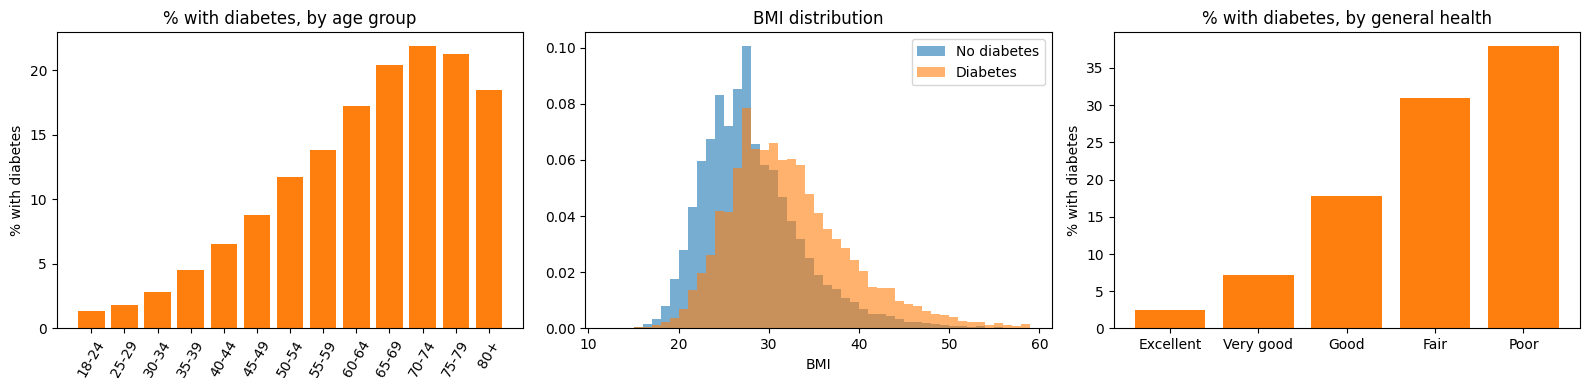

In [7]:
# Labels for the 13 age groups, so the chart is readable
AGE_LABELS = {1: '18-24', 2: '25-29', 3: '30-34', 4: '35-39', 5: '40-44', 6: '45-49',
              7: '50-54', 8: '55-59', 9: '60-64', 10: '65-69', 11: '70-74', 12: '75-79', 13: '80+'}

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# Chart 1: % with diabetes in each age group
by_age = df.groupby('Age')[TARGET].mean() * 100
axes[0].bar([AGE_LABELS[a] for a in by_age.index], by_age.values, color='tab:orange')
axes[0].set_title('% with diabetes, by age group')
axes[0].set_ylabel('% with diabetes')
axes[0].tick_params(axis='x', rotation=60)

# Chart 2: BMI for people with and without diabetes
axes[1].hist(df[df[TARGET] == 0]['BMI'], bins=range(12, 60), alpha=0.6, density=True, label='No diabetes')
axes[1].hist(df[df[TARGET] == 1]['BMI'], bins=range(12, 60), alpha=0.6, density=True, label='Diabetes')
axes[1].set_title('BMI distribution')
axes[1].set_xlabel('BMI')
axes[1].legend()

# Chart 3: % with diabetes by self-rated general health
by_health = df.groupby('GenHlth')[TARGET].mean() * 100
health_names = ['Excellent', 'Very good', 'Good', 'Fair', 'Poor']
axes[2].bar(health_names, by_health.values, color='tab:orange')
axes[2].set_title('% with diabetes, by general health')
axes[2].set_ylabel('% with diabetes')

plt.tight_layout()
plt.show()

In [8]:
# For each yes/no question: % with diabetes among people who said NO vs YES
yes_no_questions = ['HighBP', 'HighChol', 'PhysActivity', 'DiffWalk', 'Smoker',
                    'HeartDiseaseorAttack', 'Stroke', 'Sex']

table = pd.DataFrame({
    'answer = 0 (no / female)': [df[df[q] == 0][TARGET].mean() * 100 for q in yes_no_questions],
    'answer = 1 (yes / male)':  [df[df[q] == 1][TARGET].mean() * 100 for q in yes_no_questions],
}, index=yes_no_questions).round(1)

print('% of people with diabetes, depending on their answer:')
table

% of people with diabetes, depending on their answer:


,answer = 0 (no / female),answer = 1 (yes / male)
HighBP,6.0,24.4
HighChol,8.0,22.0
PhysActivity,21.1,11.6
DiffWalk,10.5,30.7
Smoker,12.1,16.3
HeartDiseaseorAttack,12.0,33.0
Stroke,13.2,31.8
Sex,13.0,15.2


**What the charts show (numbers from the run above):**
- **Age:** risk climbs steadily, from about 1% at 18-24 to about 22% at 70-74, then dips a little at 80+ (about 18%). A likely reason for the dip: people with diabetes are less likely to live past 80 and answer a phone survey.
- **BMI:** the diabetes group is shifted toward higher BMI (its peak is around 30 vs around 27 for the others), but the two groups overlap a lot. BMI alone can't separate them.
- **General health:** about 2.5% of people who say 'excellent' have diabetes vs about 38% of people who say 'poor'. This is a strong signal, but partly because having diabetes *makes* people rate their health lower (cause and effect go both ways).
- **Yes/no questions:** high blood pressure (6.0% → 24.4%), high cholesterol (8.0% → 22.0%), difficulty walking (10.5% → 30.7%), heart disease (12.0% → 33.0%) and stroke (13.2% → 31.8%) each go with much higher diabetes rates. Being physically active goes with *lower* rates (21.1% if inactive vs 11.6% if active). Smoking (12.1% → 16.3%) and sex (women 13.0%, men 15.2%) make smaller differences.

No single question is enough on its own. That's why we combine them in a model.

## 3. Split the data into train, validation and test sets

We split the 253,680 people into three groups that never overlap:

| Set | Share | What it's for |
|---|---|---|
| **Train** | 60% | The model learns patterns from these people |
| **Validation** | 20% | We use these to compare models and **choose the threshold**. It's our 'practice exam' |
| **Test** | 20% | Locked away. We use it **only once, at the very end**, for the final results table. It's the 'real exam' |

**Why a separate test set?** Every time we look at results and change something, we slowly 'tune' to that data. If we did that on the test set, our final score would look better than the model really is. Keeping the test set locked gives an honest score.

**Stratified** means each set keeps the same 13.9% share of diabetics, so no set gets 'lucky' with more or fewer diabetics.

In [9]:
from sklearn.model_selection import train_test_split

X = df[FEATURES]   # the answers (inputs)
y = df[TARGET]     # diabetes yes/no (what we want to predict)

# Step 1: cut off 20% as the locked TEST set
X_rest, X_test, y_rest, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_SEED)

# Step 2: split the remaining 80% into TRAIN (60% of all) and VALIDATION (20% of all)
# 0.25 of the remaining 80% = 20% of everyone
X_train, X_val, y_train, y_val = train_test_split(
    X_rest, y_rest, test_size=0.25, stratify=y_rest, random_state=RANDOM_SEED)

for name, part_y in [('Train', y_train), ('Validation', y_val), ('Test', y_test)]:
    print(f'{name:<11} {len(part_y):>7,} people   {part_y.mean():.1%} with diabetes   ({part_y.sum():,} diabetics)')

Train       152,208 people   13.9% with diabetes   (21,208 diabetics)
Validation   50,736 people   13.9% with diabetes   (7,069 diabetics)
Test         50,736 people   13.9% with diabetes   (7,069 diabetics)


### 3a. The 'twin' check: how many test people have an identical twin in the training set?

In Section 2 we found that 67% of rows are exact duplicates of another row. So many people in the test set give **exactly the same 11 answers** as someone in the training set.

This is not cheating (they are different real people), but a model could just 'remember' those answer patterns. So we mark every test person as **seen** (their pattern appears in training) or **unseen** (a brand-new pattern). At the end, we'll check the model works on *both* groups. A pharmacist will meet plenty of 'unseen' customers.

In [10]:
# All the different answer patterns that appear in the training set
train_patterns = X_train.drop_duplicates().copy()
train_patterns['seen_in_train'] = True

# For each test person: does their exact pattern appear in training?
test_seen = X_test.merge(train_patterns, on=FEATURES, how='left')['seen_in_train']
test_seen = test_seen.notna().values   # True if a match was found, False if not

print(f'Test people whose answers match someone in training: {test_seen.mean():.1%}')
print(f'Test people with a brand-new answer pattern:         {(~test_seen).mean():.1%}  ({(~test_seen).sum():,} people)')

Test people whose answers match someone in training: 79.7%
Test people with a brand-new answer pattern:         20.3%  (10,309 people)


## 4. A helper to measure screening results

We'll score every method (baselines and models) the same way. For a screening tool, these are the numbers that matter:

| Measure | Plain meaning | Why we care |
|---|---|---|
| **Recall** (sensitivity) | Of all the real diabetics, what % did we flag? | **Most important.** A missed diabetic goes home thinking they're fine |
| **Precision** | Of the people we flagged, what % really have diabetes? | Low precision = many false alarms = wasted doctor visits |
| **False negatives (FN)** | Diabetics we told 'low risk' | The dangerous mistake |
| **False positives (FP)** | Healthy people we sent for a test | The annoying (but safe) mistake. An HbA1c test is cheap and simple |
| **Flagged %** | What share of all customers we'd send to a doctor | Tells us if the tool is practical |
| **ROC-AUC** | How well the method *ranks* people from low to high risk (0.5 = coin flip, 1.0 = perfect) | Doesn't depend on the threshold |
| **Accuracy** | % of all answers that were right | Shown only to prove it's misleading here |

In [11]:
from sklearn.metrics import confusion_matrix, roc_auc_score

def screening_metrics(y_true, y_pred, risk_score=None):
    """Return the screening numbers for one method.
    y_true: real answers (0/1). y_pred: our flags (0/1).
    risk_score: optional number per person (higher = riskier), used for ROC-AUC."""
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    results = {
        'Recall':      tp / (tp + fn),
        'Precision':   tp / (tp + fp) if (tp + fp) > 0 else 0.0,   # 0 if we never flag anyone
        'False neg':   fn,
        'False pos':   fp,
        'Flagged %':   (tp + fp) / len(y_true),
        'Accuracy':    (tp + tn) / len(y_true),
    }
    if risk_score is not None:
        results['ROC-AUC'] = roc_auc_score(y_true, risk_score)
    return results

print('Helper ready.')

Helper ready.


## 5. Baseline 1: always say 'no diabetes'

A **baseline** is the simplest possible method. Any real model must beat it, or it's useless.

Baseline 1 is the laziest tool imaginable: it tells **every** customer 'low risk'. We score it on the **validation** set (the test set stays locked until the final table).

In [12]:
# Predict 0 ('no diabetes') for every person in the validation set
baseline1_pred = np.zeros(len(y_val), dtype=int)
# Every person gets the same risk score, so the ranking is no better than a coin flip
baseline1_score = np.zeros(len(y_val))

b1 = screening_metrics(y_val, baseline1_pred, baseline1_score)
for measure, value in b1.items():
    print(f'{measure:<10} {value:.3f}' if isinstance(value, float) else f'{measure:<10} {value:,}')

Recall     0.000
Precision  0.000
False neg  7,069
False pos  0
Flagged %  0.000
Accuracy   0.861
ROC-AUC    0.500


**Why accuracy is misleading here:** Baseline 1 scores about **86% accuracy**, which sounds good. But its **recall is 0**: it catches **zero** diabetics, and every one of them is a false negative. It's a tool that never does its one job.

This happens because only 14% of people have diabetes, so saying 'no' to everyone is right 86% of the time. **From now on we judge methods by recall, precision and the counts of each mistake, not accuracy.**

## 6. Baseline 2: the American Diabetes Association (ADA) risk test

This is **the important baseline**. Doctors and pharmacists already have a free paper checklist: the ADA's 7-question **Type 2 Diabetes Risk Test**. If our AI model can't beat a paper checklist, there's no reason to use it.

### How the real ADA test scores people

| Question | Points | Can we use it? |
|---|---|---|
| Age: under 40 / 40-49 / 50-59 / 60+ | 0 / 1 / 2 / 3 | ✅ from `Age` groups |
| Are you a man? | 1 | ✅ from `Sex` |
| Have you ever been diagnosed with high blood pressure? | 1 | ✅ from `HighBP` |
| Are you physically active? (No = 1 point) | 1 | ✅ from `PhysActivity` |
| Weight for your height (BMI): about 25-29.9 / 30-39.9 / 40+ | 1 / 2 / 3 | ✅ from `BMI` (the real test uses a height-weight chart, which matches these BMI bands closely) |
| Does your mother, father, sister or brother have diabetes? | 1 | ❌ **not in the dataset** |
| (Women) Have you ever had gestational diabetes (diabetes during pregnancy)? | 1 | ❌ **not in the dataset** |

**Score 5 or more = high risk** (go see a doctor).

### What our version is missing (and why it matters)
- **Family history** and **gestational diabetes** aren't in the CDC survey data. Both questions can only *add* points, never remove them.
- So our version gives some people a **lower score than the real test would**. Someone who scores 4 with us might score 5 or 6 on the real test. This means our Baseline 2 is a bit *weaker* than the real ADA test. We must say this honestly when we compare.
- To be fair to the ADA test, we'll also try a cutoff of **4 or more**, to make up a little for the 2 missing questions.
- The age groups line up perfectly: group 5 starts at 40, group 7 at 50, and group 9 at 60.

In [13]:
def ada_score(X):
    """Our approximation of the ADA 7-question risk test, using the 5 questions we have.
    Takes a table of people and returns one score per person (0 to 9)."""
    score = np.zeros(len(X), dtype=int)

    # Age points: Age groups 1-4 = under 40, 5-6 = 40-49, 7-8 = 50-59, 9-13 = 60+
    age = X['Age'].values
    score += np.where(age >= 9, 3, np.where(age >= 7, 2, np.where(age >= 5, 1, 0)))

    # 1 point for being male (Sex: 1 = male)
    score += X['Sex'].values.astype(int)

    # 1 point for high blood pressure
    score += X['HighBP'].values.astype(int)

    # 1 point for NOT being physically active (PhysActivity: 0 = not active)
    score += (X['PhysActivity'].values == 0).astype(int)

    # BMI points: 25-29.9 = 1, 30-39.9 = 2, 40+ = 3
    bmi = X['BMI'].values
    score += np.where(bmi >= 40, 3, np.where(bmi >= 30, 2, np.where(bmi >= 25, 1, 0)))

    return score

# Try it on 3 example people from the validation set, so we can check the points by hand
examples = X_val.head(3).copy()
examples['ADA score'] = ada_score(examples)
examples[['Age', 'Sex', 'HighBP', 'PhysActivity', 'BMI', 'ADA score']]

,Age,Sex,HighBP,PhysActivity,BMI,ADA score
125910,9,1,0,1,33,6
153203,2,0,1,1,29,2
185915,11,0,1,1,19,4


**Check by hand:** for each example row above, add up: age points (group 1-4 → 0, 5-6 → 1, 7-8 → 2, 9+ → 3), +1 if `Sex` = 1, +1 if `HighBP` = 1, +1 if `PhysActivity` = 0, and BMI points (25-29 → 1, 30-39 → 2, 40+ → 3). It should match the `ADA score` column.

### 6a. How well does the ADA score work? (validation set)

In [14]:
val_ada = ada_score(X_val)

# Official rule: score 5 or more = high risk
b2 = screening_metrics(y_val, (val_ada >= 5).astype(int), risk_score=val_ada)
# Fairer version: score 4 or more, to make up for the 2 missing questions
b2_cut4 = screening_metrics(y_val, (val_ada >= 4).astype(int), risk_score=val_ada)

comparison = pd.DataFrame({
    'Baseline 1 (always no)': b1,
    'ADA score >= 5 (official)': b2,
    'ADA score >= 4 (adjusted)': b2_cut4,
}).T
# show the mistake counts as whole numbers (not 7069.0)
comparison[["False neg", "False pos"]] = comparison[["False neg", "False pos"]].astype(int)
comparison

,Recall,Precision,False neg,False pos,Flagged %,Accuracy,ROC-AUC
Baseline 1 (always no),0.000000,0.000000,7069,0,0.000000,0.860671,0.500000
ADA score >= 5 (official),0.806903,0.237429,1365,18320,0.473510,0.612011,0.757949
ADA score >= 4 (adjusted),0.928703,0.195079,504,27088,0.663296,0.456165,0.757949


           people  % with diabetes
ADA score                         
0            1372              1.2
1            3072              1.8
2            5077              2.1
3            7562              4.3
4            9629              8.9
5            9940             15.2
6            8098             24.0
7            4592             34.4
8            1256             47.7
9             138             52.2


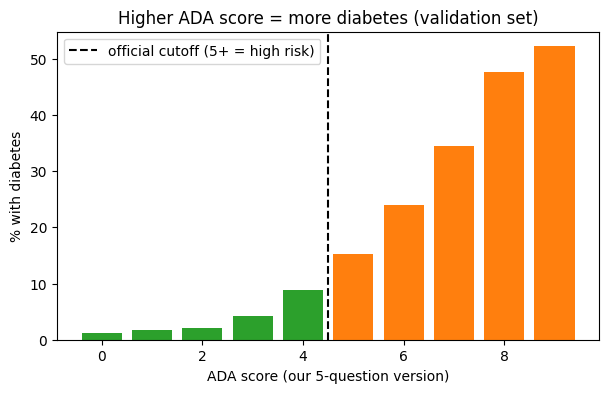

In [15]:
# For each ADA score: how many people got it, and what % of them really have diabetes?
score_table = pd.DataFrame({'ADA score': val_ada, 'diabetes': y_val.values})
by_score = score_table.groupby('ADA score')['diabetes'].agg(['count', 'mean'])
by_score.columns = ['people', '% with diabetes']
by_score['% with diabetes'] = (by_score['% with diabetes'] * 100).round(1)
print(by_score)

plt.figure(figsize=(7, 4))
colors = ['tab:orange' if s >= 5 else 'tab:green' for s in by_score.index]
plt.bar(by_score.index, by_score['% with diabetes'], color=colors)
plt.axvline(4.5, color='black', linestyle='--', label='official cutoff (5+ = high risk)')
plt.xlabel('ADA score (our 5-question version)')
plt.ylabel('% with diabetes')
plt.title('Higher ADA score = more diabetes (validation set)')
plt.legend()
plt.show()

**How to read these results:**
- The chart should show the % with diabetes rising as the score goes up. That means the ADA checklist *does* work: it ranks people sensibly. Its ROC-AUC tells us how well it ranks people (0.5 = coin flip, 1.0 = perfect).
- **Recall** tells us what share of diabetics the checklist catches. **False negatives** are the diabetics it misses.
- Moving the cutoff from 5 to 4 catches **more** diabetics (higher recall, fewer false negatives) but sends **more** healthy people to the doctor (more false positives, more flagged). This trade-off is the same one we'll face when we choose our model's threshold.

**This is the bar our AI model has to beat.** In the next section, we'll train models and compare them with the ADA score *at the same number of people flagged*. That makes it a fair fight.

## 7. Train two models

Now the AI part. We train two different kinds of model on the **training set** and compare them on the **validation set**.

### Model 1: Logistic regression
The simplest real model. It gives each question a **weight** (how much it pushes risk up or down), adds them up, and turns the total into a risk score between 0 and 1. It's like the ADA checklist, except the computer learns the best points for each answer from 152,208 people instead of a committee choosing them. Big advantage: **easy to explain**.

(The `StandardScaler` step puts all questions on the same scale first, so BMI, which goes up to 98, doesn't drown out yes/no questions that are 0 or 1.)

### Model 2: Gradient boosting (a tree-based model)
This model builds hundreds of small **decision trees**, each one a flowchart of yes/no questions like *'Is BMI over 30? Is age group over 8?'*. Each new tree tries to fix the mistakes of the trees before it. It can find **combinations** that logistic regression can't, e.g. *'high BMI matters more for older people'*. Downside: harder to explain.

### Handling class imbalance
Only 13.9% of people have diabetes. Left alone, a model learns that saying 'no' is usually safe. We use `class_weight='balanced'`, which tells the model: **a mistake on a diabetic counts about 6 times more than a mistake on a non-diabetic** (because there are about 6 non-diabetics for every diabetic). This makes the model care about catching diabetics.

**Side effect to remember:** because of this weighting, the model's output is a **risk score, not a real probability**. A score of 0.7 does **not** mean '70% chance of diabetes'. So the app will never show a percentage, only 'Low risk' or 'Higher risk'.

In [16]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier

# ---- Model 1: logistic regression ----
log_reg = make_pipeline(
    StandardScaler(),                                   # put all questions on the same scale
    LogisticRegression(class_weight='balanced', max_iter=1000)
)
log_reg.fit(X_train, y_train)                           # learn from the TRAINING set only
val_score_lr = log_reg.predict_proba(X_val)[:, 1]       # risk score for each validation person

# ---- Model 2: gradient boosting ----
gboost = HistGradientBoostingClassifier(
    class_weight='balanced',
    learning_rate=0.1,      # how big a step each new tree takes when fixing mistakes
    max_iter=200,           # number of trees
    early_stopping=False,   # always build all 200 trees (simpler to explain)
    random_state=RANDOM_SEED
)
gboost.fit(X_train, y_train)
val_score_gb = gboost.predict_proba(X_val)[:, 1]

print('Both models trained.')
print(f'Validation ROC-AUC  ADA score (5 questions): {roc_auc_score(y_val, val_ada):.3f}')
print(f'Validation ROC-AUC  Logistic regression:     {roc_auc_score(y_val, val_score_lr):.3f}')
print(f'Validation ROC-AUC  Gradient boosting:       {roc_auc_score(y_val, val_score_gb):.3f}')

Both models trained.
Validation ROC-AUC  ADA score (5 questions): 0.758
Validation ROC-AUC  Logistic regression:     0.817
Validation ROC-AUC  Gradient boosting:       0.822


### 7a. Is it too good to be true? (overfitting and leakage check)

Two things could make our results look better than they really are:
- **Overfitting:** the model memorises the training people instead of learning general patterns. Sign: much better on training data than on validation data.
- **Data leakage:** a question secretly contains the answer. Our 11 questions are all things a person knows *before* any diabetes test, and none of them is a diabetes measurement (no blood sugar, no insulin, no medication). Still, we check the scores.

For reference, published studies on this same dataset, using **all 21 questions**, usually get ROC-AUC around 0.80-0.83. With only our 11 questions, anything **much higher than about 0.83 would be suspicious**.

In [17]:
for name, model in [('Logistic regression', log_reg), ('Gradient boosting', gboost)]:
    train_auc = roc_auc_score(y_train, model.predict_proba(X_train)[:, 1])
    val_auc = roc_auc_score(y_val, model.predict_proba(X_val)[:, 1])
    print(f'{name:<20} train ROC-AUC {train_auc:.3f}   validation ROC-AUC {val_auc:.3f}   gap {train_auc - val_auc:+.3f}')

Logistic regression  train ROC-AUC 0.820   validation ROC-AUC 0.817   gap +0.003
Gradient boosting    train ROC-AUC 0.842   validation ROC-AUC 0.822   gap +0.020


**How to read this:** a gap close to 0 (say under 0.01) means the model does about as well on people it has never seen as on people it learned from, so it isn't memorising.

## 8. A fair fight: models vs. the ADA checklist at the same workload

The ADA checklist (score 5+) flagged **47.4%** of everyone and caught **80.7%** of diabetics. A model can catch more diabetics just by flagging more people, which isn't impressive. So we compare in two fair ways:

1. **Same workload:** if the model flags the **same 47.4%** of people, what % of diabetics does it catch?
2. **Same catch rate:** to catch the **same 80.7%** of diabetics, what % of people does the model need to flag? (Lower = fewer wasted doctor visits.)

We can do this because the models give a risk score, and we choose where to draw the line. (Choosing *our* line properly is the next section.)

In [18]:
def recall_when_flagging(y_true, risk_score, flag_share):
    """Flag the riskiest `flag_share` of people. Return (recall, share actually flagged)."""
    cutoff = np.quantile(risk_score, 1 - flag_share)
    flagged = risk_score >= cutoff
    return flagged[y_true == 1].mean(), flagged.mean()

def flagged_share_for_recall(y_true, risk_score, target_recall):
    """Find the line that catches `target_recall` of diabetics. Return (share flagged, recall)."""
    cutoff = np.quantile(risk_score[y_true == 1], 1 - target_recall)
    flagged = risk_score >= cutoff
    return flagged.mean(), flagged[y_true == 1].mean()

y_val_arr = y_val.values
n_diabetics = int(y_val_arr.sum())
ada_flag_share = b2['Flagged %']   # 47.4%
ada_recall = b2['Recall']          # 80.7%

rows = {'ADA score >= 5': {
    'ROC-AUC': roc_auc_score(y_val_arr, val_ada),
    'Recall at ADA workload': ada_recall,
    'Diabetics missed at ADA workload': int(round((1 - ada_recall) * n_diabetics)),
    'Flagged % needed for ADA recall': ada_flag_share,
    'Actual flagged % at ADA workload': ada_flag_share,
}}
for name, score in [('Logistic regression', val_score_lr), ('Gradient boosting', val_score_gb)]:
    recall, actual_share = recall_when_flagging(y_val_arr, score, ada_flag_share)
    share, _ = flagged_share_for_recall(y_val_arr, score, ada_recall)
    rows[name] = {
        'ROC-AUC': roc_auc_score(y_val_arr, score),
        'Recall at ADA workload': recall,
        'Diabetics missed at ADA workload': int(round((1 - recall) * n_diabetics)),
        'Flagged % needed for ADA recall': share,
        # many people share the same score, so the real flagged share can be slightly above 47.4%
        'Actual flagged % at ADA workload': actual_share,
    }

fair_fight = pd.DataFrame(rows).T
fair_fight['Diabetics missed at ADA workload'] = fair_fight['Diabetics missed at ADA workload'].astype(int)
print(f'Validation set: {len(y_val_arr):,} people, {n_diabetics:,} diabetics\n')
fair_fight.round(3)

Validation set: 50,736 people, 7,069 diabetics



,ROC-AUC,Recall at ADA workload,Diabetics missed at ADA workload,Flagged % needed for ADA recall,Actual flagged % at ADA workload
ADA score >= 5,0.758,0.807,1365,0.474,0.474
Logistic regression,0.817,0.876,878,0.388,0.474
Gradient boosting,0.822,0.879,855,0.384,0.474


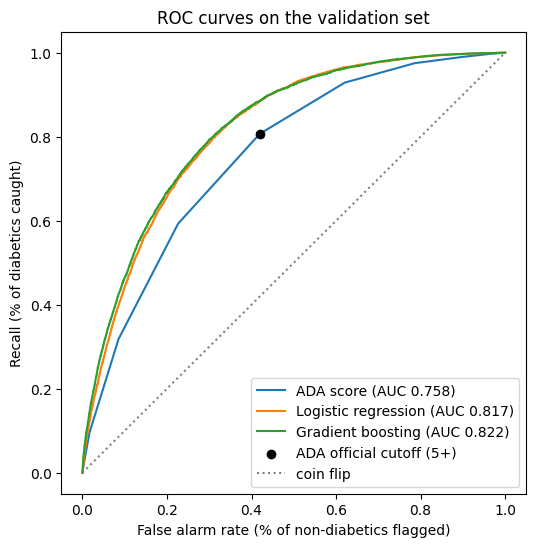

In [19]:
from sklearn.metrics import roc_curve

# ROC curve: for every possible line, % of diabetics caught (up) vs % of non-diabetics falsely flagged (right)
plt.figure(figsize=(6, 6))
for name, score in [('ADA score', val_ada), ('Logistic regression', val_score_lr), ('Gradient boosting', val_score_gb)]:
    false_alarm_rate, catch_rate, _ = roc_curve(y_val_arr, score)
    plt.plot(false_alarm_rate, catch_rate, label=f'{name} (AUC {roc_auc_score(y_val_arr, score):.3f})')

# Mark where the official ADA rule (score >= 5) sits
ada_flags = val_ada >= 5
plt.scatter(ada_flags[y_val_arr == 0].mean(), ada_flags[y_val_arr == 1].mean(),
            color='black', zorder=5, label='ADA official cutoff (5+)')
plt.plot([0, 1], [0, 1], color='grey', linestyle=':', label='coin flip')
plt.xlabel('False alarm rate (% of non-diabetics flagged)')
plt.ylabel('Recall (% of diabetics caught)')
plt.title('ROC curves on the validation set')
plt.legend(loc='lower right')
plt.show()

**How to read the fair fight:**
- **Recall at ADA workload:** higher is better. Each extra percentage point means about 70 more diabetics caught out of 7,069, with the *same* number of doctor referrals.
- **Flagged % needed for ADA recall:** lower is better. It means the same diabetics are caught but fewer healthy people get sent to the doctor.
- **ROC curves:** the higher a curve sits, the better the method. A curve above the black dot beats the ADA rule at that workload.

### What we found (validation set, 50,736 people, 7,069 diabetics)

| | ROC-AUC | Diabetics caught when flagging 47.4% | Missed | % flagged to catch 80.7% |
|---|---|---|---|---|
| ADA score ≥ 5 | 0.758 | 80.7% | 1,365 | 47.4% |
| Logistic regression | 0.817 | 87.6% | 878 | 38.8% |
| Gradient boosting | 0.822 | 87.9% | 855 | 38.4% |

- **Both models beat the ADA checklist.** With the *same* number of referrals, logistic regression catches **487 more diabetics** (1,365 → 878 missed). Or, catching the *same* diabetics, it flags **38.8% instead of 47.4%** of people: about **4,400 fewer** unnecessary referrals out of 50,736.
- **Not too good to be true:** the scores (0.817 and 0.822) are in the normal range for this dataset, and logistic regression does almost exactly as well on new people as on training people (gap 0.003). Gradient boosting has a slightly bigger gap (0.020): it memorises a little, but still does well on new people.
- **Gradient boosting is only a tiny bit better** (0.822 vs 0.817, and 23 more diabetics caught out of 7,069).

**Honest caveat:** the comparison isn't perfectly equal. Our models use **11 questions**, while our ADA version uses only **5** (it's missing family history and gestational diabetes). Part of the models' advantage comes from the extra questions (general health, cholesterol, difficulty walking, heart disease, stroke), not only from 'AI'. The real 7-question ADA test would probably do a bit better than our 5-question version.

**Our choice: logistic regression for the app.** It's almost as good as gradient boosting, it doesn't overfit, and it's **much easier to explain**: each answer has one weight, so we can show a customer exactly why they were flagged. For a health tool used by pharmacists, being explainable matters more than a 0.005 gain in ROC-AUC. We'll still report both models in the final test table.

## 9. Choosing the threshold (where 'low risk' becomes 'see a doctor')

The model gives every person a **risk score** between 0 and 1. We have to choose a **threshold**: everyone with a score at or above it is told *'Higher risk: see a doctor for an HbA1c test'*.

- **Low threshold** → we flag lots of people → we catch almost every diabetic (high recall), but send many healthy people to the doctor (low precision).
- **High threshold** → we flag few people → fewer false alarms, but we **miss** more diabetics.

### Which mistake is worse?
- A **missed diabetic** (false negative) goes home thinking they're fine. Untreated diabetes can quietly damage eyes, kidneys, nerves and the heart for years. **This is the expensive mistake.**
- A **false alarm** (false positive) costs one quick HbA1c blood test. It's cheap, and the person still gets useful health advice. **This is the cheap mistake.**

So we want **high recall**. But we can't flag everyone: if the tool sends 80% of customers to the doctor, pharmacists will stop trusting it, and clinics will be flooded.

### Our rule
We choose the threshold on the **validation set** (never the test set) with this rule:

> **Catch at least 85% of diabetics**, which is more than the ADA checklist's 80.7%, **while flagging fewer people than the ADA checklist** (47.4%).

That way our tool is better than the checklist on **both** counts at once: fewer missed diabetics *and* fewer unnecessary referrals. First, let's see the options.

In [20]:
def threshold_for_recall(y_true, risk_score, target_recall):
    """The highest threshold that still catches at least `target_recall` of diabetics."""
    diabetic_scores = np.sort(risk_score[y_true == 1])            # scores of real diabetics, low to high
    n_can_miss = int(np.floor((1 - target_recall) * len(diabetic_scores)))  # how many we're allowed to miss
    return diabetic_scores[n_can_miss]                            # everyone at or above this is flagged

# Show what happens at different recall targets (logistic regression, validation set)
option_rows = {}
for target in [0.75, 0.80, 0.85, 0.90, 0.95]:
    t = threshold_for_recall(y_val_arr, val_score_lr, target)
    m = screening_metrics(y_val_arr, (val_score_lr >= t).astype(int))
    option_rows[f'catch {target:.0%}'] = {'threshold': t, **m}

options = pd.DataFrame(option_rows).T
options[['False neg', 'False pos']] = options[['False neg', 'False pos']].astype(int)
print('Logistic regression on the validation set (7,069 diabetics, 50,736 people)')
print('For comparison, ADA checklist 5+: recall 0.807, flagged 0.474, precision 0.237\n')
options[['threshold', 'Recall', 'Precision', 'False neg', 'False pos', 'Flagged %']].round(3)

Logistic regression on the validation set (7,069 diabetics, 50,736 people)
For comparison, ADA checklist 5+: recall 0.807, flagged 0.474, precision 0.237



,threshold,Recall,Precision,False neg,False pos,Flagged %
catch 75%,0.506,0.75,0.311,1766,11757,0.336
catch 80%,0.457,0.80,0.292,1413,13681,0.381
catch 85%,0.402,0.85,0.272,1060,16117,0.436
catch 90%,0.329,0.90,0.246,706,19451,0.509
catch 95%,0.236,0.95,0.214,353,24666,0.619


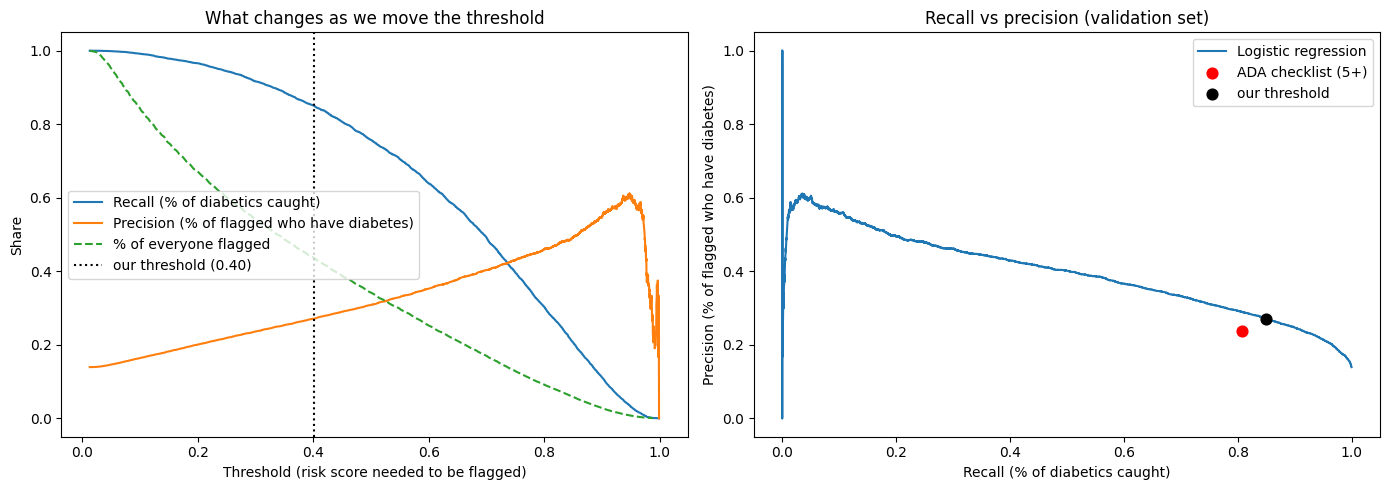

In [21]:
from sklearn.metrics import precision_recall_curve

precision, recall, thresholds = precision_recall_curve(y_val_arr, val_score_lr)
# share of all people flagged at each threshold
flagged_share = np.array([(val_score_lr >= t).mean() for t in thresholds[::50]])

TARGET_RECALL = 0.85
chosen_threshold = threshold_for_recall(y_val_arr, val_score_lr, TARGET_RECALL)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left: recall, precision and % flagged as the threshold changes
axes[0].plot(thresholds, recall[:-1], label='Recall (% of diabetics caught)')
axes[0].plot(thresholds, precision[:-1], label='Precision (% of flagged who have diabetes)')
axes[0].plot(thresholds[::50], flagged_share, label='% of everyone flagged', linestyle='--')
axes[0].axvline(chosen_threshold, color='black', linestyle=':', label=f'our threshold ({chosen_threshold:.2f})')
axes[0].set_xlabel('Threshold (risk score needed to be flagged)')
axes[0].set_ylabel('Share')
axes[0].set_title('What changes as we move the threshold')
axes[0].legend()

# Right: the classic recall vs precision curve, with the ADA checklist and our choice marked
axes[1].plot(recall, precision, label='Logistic regression')
axes[1].scatter(b2['Recall'], b2['Precision'], color='red', zorder=5, s=60, label='ADA checklist (5+)')
chosen = screening_metrics(y_val_arr, (val_score_lr >= chosen_threshold).astype(int))
axes[1].scatter(chosen['Recall'], chosen['Precision'], color='black', zorder=5, s=60, label='our threshold')
axes[1].set_xlabel('Recall (% of diabetics caught)')
axes[1].set_ylabel('Precision (% of flagged who have diabetes)')
axes[1].set_title('Recall vs precision (validation set)')
axes[1].legend()

plt.tight_layout()
plt.show()

### 9a. Our chosen threshold

We lock in the threshold that catches 85% of diabetics on the validation set, for **both** models (each model gets its own threshold, because their scores are on different scales). Then we check it meets our rule: recall at least 85% **and** fewer people flagged than the ADA checklist.

In [22]:
THRESHOLD_LR = threshold_for_recall(y_val_arr, val_score_lr, TARGET_RECALL)
THRESHOLD_GB = threshold_for_recall(y_val_arr, val_score_gb, TARGET_RECALL)

val_results = pd.DataFrame({
    'ADA score >= 5': b2,
    f'Logistic regression (threshold {THRESHOLD_LR:.3f})': screening_metrics(
        y_val_arr, (val_score_lr >= THRESHOLD_LR).astype(int), val_score_lr),
    f'Gradient boosting (threshold {THRESHOLD_GB:.3f})': screening_metrics(
        y_val_arr, (val_score_gb >= THRESHOLD_GB).astype(int), val_score_gb),
}).T
val_results[['False neg', 'False pos']] = val_results[['False neg', 'False pos']].astype(int)
display(val_results.round(3))

lr_row = val_results.iloc[1]
print('Does logistic regression meet our rule?')
print(f"  Recall at least 85%:              {lr_row['Recall']:.1%}  ->  {lr_row['Recall'] >= 0.85}")
print(f"  Flags fewer people than ADA (47.4%): {lr_row['Flagged %']:.1%}  ->  {lr_row['Flagged %'] < b2['Flagged %']}")

,Recall,Precision,False neg,False pos,Flagged %,Accuracy,ROC-AUC
ADA score >= 5,0.807,0.237,1365,18320,0.474,0.612,0.758
Logistic regression (threshold 0.402),0.850,0.272,1060,16117,0.436,0.661,0.817
Gradient boosting (threshold 0.417),0.850,0.274,1059,15964,0.433,0.664,0.822


Does logistic regression meet our rule?
  Recall at least 85%:              85.0%  ->  True
  Flags fewer people than ADA (47.4%): 43.6%  ->  True


### What we chose, in plain words

**Threshold for logistic regression: 0.402** (gradient boosting: 0.417). A customer whose risk score is 0.402 or higher is told to see a doctor for an HbA1c test.

On the validation set (50,736 people, 7,069 diabetics), compared with the ADA checklist:

| | ADA checklist (5+) | Our model (threshold 0.402) |
|---|---|---|
| Diabetics caught (recall) | 80.7% | **85.0%** |
| Diabetics missed | 1,365 | **1,060** (305 fewer) |
| Healthy people sent to a doctor | 18,320 | **16,117** (2,203 fewer) |
| Share of all customers flagged | 47.4% | **43.6%** |
| Of those flagged, % who really have diabetes | 23.7% | **27.2%** |

**Our rule is met: the model is better than the checklist on both counts at once.** It misses fewer diabetics *and* sends fewer healthy people to the doctor.

**Why 85% and not 90% or 95%?** Look at the options table: going from 85% to 90% would catch 354 more diabetics, but cost 3,334 more false alarms, and we'd flag 50.9% of everyone, which is *more* than the ADA checklist. At 95%, we'd flag 61.9% of customers. 85% is the highest of our options where we still beat the checklist on workload.

**What this means for a pharmacist:** out of every 100 customers checked, about 44 would be told to get a blood test. About 12 of those 44 would really have diabetes. Of the 14 diabetics in every 100 customers, about 12 would be caught and about 2 missed.

**Honest point:** 44 out of 100 is still a lot of referrals. That's the price of catching most diabetics with questions alone, without a blood test. A finger-prick blood test at the pharmacy could be a cheaper second step for flagged people (see 'What we'd do next').

## 10. Final results on the test set (used only once)

Until now, every decision (which questions, which model, which threshold) was made using the training and validation sets only. The **test set** (50,736 people, 7,069 diabetics) has been locked away the whole time.

Now we unlock it **once**. Everything is frozen: the models, the threshold 0.402 (logistic regression) and 0.417 (gradient boosting), and the ADA rule (5+). **We will not change anything after seeing these numbers.** If we did, the test set would stop being an honest exam.

**What each column means:** Recall = % of diabetics caught. Precision = % of flagged people who really have diabetes. False neg = diabetics we missed. False pos = healthy people we sent to a doctor. Flagged % = share of all customers sent for a test. ROC-AUC = how well the method ranks people (0.5 = coin flip).

In [23]:
y_test_arr = y_test.values

# Risk scores for every test person (models are already trained, nothing is re-fitted)
test_ada = ada_score(X_test)
test_score_lr = log_reg.predict_proba(X_test)[:, 1]
test_score_gb = gboost.predict_proba(X_test)[:, 1]

final = pd.DataFrame({
    'Baseline 1: always no': screening_metrics(
        y_test_arr, np.zeros(len(y_test_arr), dtype=int), np.zeros(len(y_test_arr))),
    'Baseline 2: ADA score >= 5': screening_metrics(
        y_test_arr, (test_ada >= 5).astype(int), test_ada),
    f'Logistic regression (>= {THRESHOLD_LR:.3f})': screening_metrics(
        y_test_arr, (test_score_lr >= THRESHOLD_LR).astype(int), test_score_lr),
    f'Gradient boosting (>= {THRESHOLD_GB:.3f})': screening_metrics(
        y_test_arr, (test_score_gb >= THRESHOLD_GB).astype(int), test_score_gb),
}).T
final[['False neg', 'False pos']] = final[['False neg', 'False pos']].astype(int)
final = final[['Recall', 'Precision', 'False neg', 'False pos', 'Flagged %', 'ROC-AUC', 'Accuracy']]

print(f'TEST SET: {len(y_test_arr):,} people, {int(y_test_arr.sum()):,} diabetics\n')
final.round(3)

TEST SET: 50,736 people, 7,069 diabetics



,Recall,Precision,False neg,False pos,Flagged %,ROC-AUC,Accuracy
Baseline 1: always no,0.000,0.000,7069,0,0.000,0.500,0.861
Baseline 2: ADA score >= 5,0.812,0.237,1331,18450,0.477,0.757,0.610
Logistic regression (>= 0.402),0.849,0.271,1065,16145,0.437,0.815,0.661
Gradient boosting (>= 0.417),0.851,0.274,1052,15950,0.433,0.820,0.665


### 10a. Did the results hold up? (validation vs. test)

If the test numbers are close to the validation numbers, our threshold choice wasn't just lucky on one set of people. A big drop would be a warning sign.

In [24]:
lr_val = screening_metrics(y_val_arr, (val_score_lr >= THRESHOLD_LR).astype(int), val_score_lr)
lr_test = final.iloc[2]

stability = pd.DataFrame({
    'Validation': {k: lr_val[k] for k in ['Recall', 'Precision', 'Flagged %', 'ROC-AUC']},
    'Test':       {k: lr_test[k] for k in ['Recall', 'Precision', 'Flagged %', 'ROC-AUC']},
})
stability['Difference'] = stability['Test'] - stability['Validation']
print('Logistic regression, same threshold (0.402) on both sets:')
stability.round(3)

Logistic regression, same threshold (0.402) on both sets:


,Validation,Test,Difference
Recall,0.850,0.849,-0.001
Precision,0.272,0.271,-0.001
Flagged %,0.436,0.437,0.000
ROC-AUC,0.817,0.815,-0.002


### 10b. The twin check: does the model work on brand-new answer patterns?

Back in Section 3a we found that **79.7%** of test people gave exactly the same 11 answers as someone in the training set, and **20.3% (10,309 people)** had a brand-new pattern.

If the model were just memorising answer patterns, it would do well on the 'seen' group and badly on the 'unseen' group. Here we compare them.

**False alarm rate** = % of non-diabetics we wrongly flag (lower is better). We use it here instead of precision, because precision changes when a group has more or fewer diabetics, which makes groups hard to compare. We'll use the same measure in the fairness check.

In [25]:
def group_report(y_true, flags, risk_score):
    """Numbers we compare between groups of people."""
    tn, fp, fn, tp = confusion_matrix(y_true, flags, labels=[0, 1]).ravel()
    return {
        'People': len(y_true),
        'Diabetics': int(tp + fn),
        '% diabetic': (tp + fn) / len(y_true),
        'Recall': tp / (tp + fn),
        'False alarm rate': fp / (fp + tn),
        'ROC-AUC': roc_auc_score(y_true, risk_score),
    }

test_flags_lr = (test_score_lr >= THRESHOLD_LR).astype(int)

twin_check = pd.DataFrame({
    'Seen pattern (twin in training)': group_report(
        y_test_arr[test_seen], test_flags_lr[test_seen], test_score_lr[test_seen]),
    'Brand-new pattern': group_report(
        y_test_arr[~test_seen], test_flags_lr[~test_seen], test_score_lr[~test_seen]),
}).T
twin_check[['People', 'Diabetics']] = twin_check[['People', 'Diabetics']].astype(int)
print('Logistic regression on the test set, split by whether the answer pattern appeared in training:')
twin_check.round(3)

Logistic regression on the test set, split by whether the answer pattern appeared in training:


,People,Diabetics,% diabetic,Recall,False alarm rate,ROC-AUC
Seen pattern (twin in training),40427,4568,0.113,0.803,0.308,0.821
Brand-new pattern,10309,2501,0.243,0.933,0.655,0.743


### What the final test results mean

**Main result (test set: 50,736 people, 7,069 diabetics):**

| | Diabetics caught | Missed | Healthy people sent to a doctor | % flagged | ROC-AUC |
|---|---|---|---|---|---|
| Baseline 1: always no | 0% | 7,069 | 0 | 0% | 0.500 |
| Baseline 2: ADA checklist (5+) | 81.2% | 1,331 | 18,450 | 47.7% | 0.757 |
| **Logistic regression (our app)** | **84.9%** | **1,065** | **16,145** | **43.7%** | **0.815** |
| Gradient boosting | 85.1% | 1,052 | 15,950 | 43.3% | 0.820 |

- **Our model beats the ADA checklist on new people it has never seen:** **266 fewer diabetics missed** *and* **2,305 fewer healthy people sent to a doctor**, out of 50,736.
- **Accuracy is misleading:** 'always no' has the *highest* accuracy (0.861), yet catches nobody. The ADA checklist has the *lowest* accuracy (0.610), yet catches 81% of diabetics.
- **Gradient boosting is again only slightly better** (13 fewer missed out of 7,069). We keep logistic regression for the app because it's easier to explain.

**The results held up:** validation and test numbers differ by at most 0.002, so our threshold choice wasn't lucky.

**The twin check: the model works differently on unusual people.**

| Test people | People | % diabetic | Recall | False alarm rate | ROC-AUC |
|---|---|---|---|---|---|
| Answer pattern seen in training | 40,427 | 11.3% | 80.3% | 30.8% | 0.821 |
| Brand-new answer pattern | 10,309 | 24.3% | 93.3% | 65.5% | 0.743 |

- The brand-new patterns are **not random people**. They are more *unusual* (rare combinations of answers, more health problems), and **twice as likely to be diabetic** (24.3% vs 11.3%).
- For these people, the model catches **93%** of diabetics, but it also flags **two-thirds of the healthy ones**. It ranks them less well (ROC-AUC 0.743 vs 0.821).
- **This is not memorising.** Logistic regression has only 11 weights. It can't store answer patterns, and its train-validation gap was only 0.003. The reason is that many unusual people have several risk factors at once, so almost everyone in that group *looks* high-risk, and it's harder to tell them apart.
- **What it means in practice:** for customers with unusual health profiles, the tool leans toward 'see a doctor'. That's the safe direction for a screening tool, but it means more false alarms for this group.

## 11. Fairness check: does the tool work equally well for everyone?

A screening tool could look good overall but fail one group of people, e.g. catch most diabetic men but miss many diabetic women. In a pharmacy, that would mean one group gets worse care.

We check our app's model (logistic regression, threshold 0.402) on the **test set**, split by:
- **Sex:** female / male
- **Age group:** 18-39, 40-49, 50-59, 60-69, 70+ (built from the 13 age codes)

For each group we look at two numbers:
- **Recall:** % of diabetics in that group we catch. A low number means that group's diabetics are being **missed**.
- **False alarm rate:** % of non-diabetics in that group we wrongly send to a doctor. A high number means that group gets **more unnecessary referrals**.

(Remember from 10b: we use false alarm rate instead of precision, because precision changes with how common diabetes is in each group.)

In [26]:
# Turn the 13 age codes into 5 easy-to-read age groups
AGE_BANDS = {'18-39': [1, 2, 3, 4], '40-49': [5, 6], '50-59': [7, 8], '60-69': [9, 10], '70+': [11, 12, 13]}

def age_band(age_codes):
    bands = np.empty(len(age_codes), dtype=object)
    for band, codes in AGE_BANDS.items():
        bands[np.isin(age_codes, codes)] = band
    return bands

def fairness_table(groups, y_true, flags, risk_score, order):
    """One row of group_report() numbers for each group."""
    rows = {g: group_report(y_true[groups == g], flags[groups == g], risk_score[groups == g]) for g in order}
    table = pd.DataFrame(rows).T
    table[['People', 'Diabetics']] = table[['People', 'Diabetics']].astype(int)
    return table

test_age_band = age_band(X_test['Age'].values)
test_sex = np.where(X_test['Sex'].values == 1, 'Male', 'Female')

by_sex = fairness_table(test_sex, y_test_arr, test_flags_lr, test_score_lr, ['Female', 'Male'])
by_age = fairness_table(test_age_band, y_test_arr, test_flags_lr, test_score_lr, list(AGE_BANDS))

print(f'Overall on the test set: recall {test_flags_lr[y_test_arr == 1].mean():.3f}, '
      f'false alarm rate {test_flags_lr[y_test_arr == 0].mean():.3f}')
print('\nBy sex:')
display(by_sex.round(3))
print('By age group:')
display(by_age.round(3))

Overall on the test set: recall 0.849, false alarm rate 0.370

By sex:


,People,Diabetics,% diabetic,Recall,False alarm rate,ROC-AUC
Female,28531,3685,0.129,0.837,0.339,0.825
Male,22205,3384,0.152,0.863,0.411,0.802


By age group:


,People,Diabetics,% diabetic,Recall,False alarm rate,ROC-AUC
18-39,7749,258,0.033,0.484,0.070,0.836
40-49,7100,532,0.075,0.679,0.190,0.833
50-59,11261,1417,0.126,0.804,0.323,0.816
60-69,13222,2511,0.190,0.888,0.470,0.793
70+,11404,2351,0.206,0.914,0.680,0.719


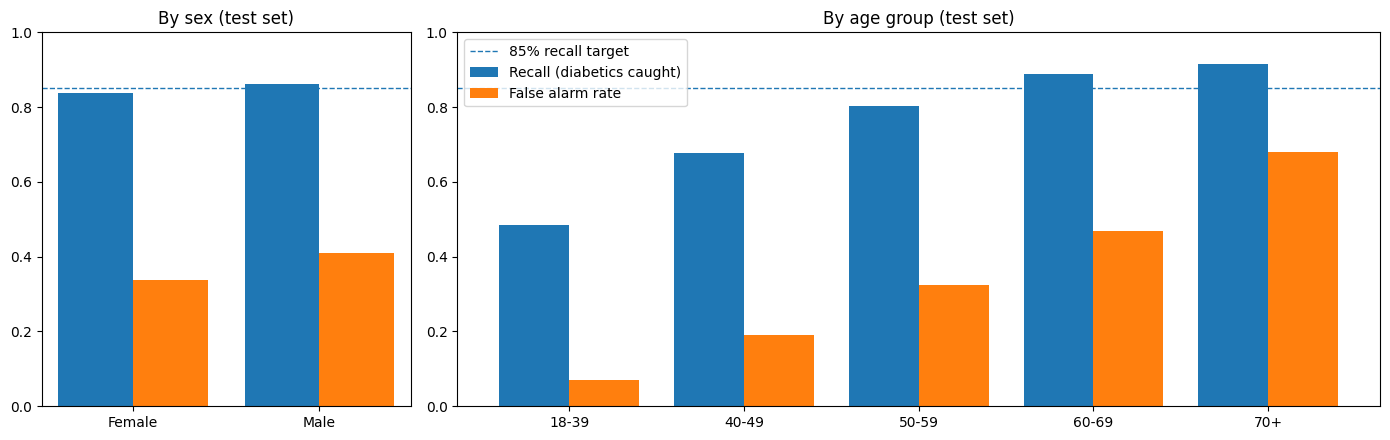

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), gridspec_kw={'width_ratios': [2, 5]})

for ax, table, title in [(axes[0], by_sex, 'By sex'), (axes[1], by_age, 'By age group')]:
    positions = np.arange(len(table))
    ax.bar(positions - 0.2, table['Recall'], width=0.4, label='Recall (diabetics caught)', color='tab:blue')
    ax.bar(positions + 0.2, table['False alarm rate'], width=0.4, label='False alarm rate', color='tab:orange')
    ax.axhline(TARGET_RECALL, color='tab:blue', linestyle='--', linewidth=1, label='85% recall target')
    ax.set_xticks(positions)
    ax.set_xticklabels(table.index)
    ax.set_ylim(0, 1)
    ax.set_title(title + ' (test set)')

axes[1].legend(loc='upper left')
plt.tight_layout()
plt.show()

### 11a. Trying one fix: a lower line for groups whose diabetics we miss

If a group's recall is below our 85% target, one simple fix is to give that group its **own, lower threshold**, so we catch more of its diabetics.

**How we do it (fairly):**
1. On the **validation** set, for each age group, find the threshold that catches 85% of that group's diabetics.
2. **Only lower** the line for groups that need it. Groups already above 85% keep the normal threshold (0.402), so nobody gets a *worse* catch rate.
3. Then measure the result on the **test** set, and report what it costs (more false alarms, more people flagged).

We try this for **age groups**, because that's where gaps are most likely, since risk depends so strongly on age. Is it OK to treat ages differently? The model already uses age, and the ADA checklist itself gives points for age. Here we use age to make sure younger diabetics aren't overlooked, not to exclude anyone.

In [28]:
val_age_band = age_band(X_val['Age'].values)

# Step 1 + 2: one threshold per age group, chosen on the VALIDATION set, never higher than the normal one
group_thresholds = {}
for band in AGE_BANDS:
    in_band = val_age_band == band
    band_threshold = threshold_for_recall(y_val_arr[in_band], val_score_lr[in_band], TARGET_RECALL)
    group_thresholds[band] = min(THRESHOLD_LR, band_threshold)

print('Threshold for each age group (normal threshold = %.3f):' % THRESHOLD_LR)
for band, t in group_thresholds.items():
    note = 'lowered' if t < THRESHOLD_LR else 'unchanged'
    print(f'  {band:<6} {t:.3f}  ({note})')

def flags_with_age_thresholds(risk_score, bands):
    """Flag each person using the threshold for their age group."""
    person_threshold = np.array([group_thresholds[b] for b in bands])
    return (risk_score >= person_threshold).astype(int)

# Step 3: apply to the TEST set
test_flags_fixed = flags_with_age_thresholds(test_score_lr, test_age_band)
by_age_fixed = fairness_table(test_age_band, y_test_arr, test_flags_fixed, test_score_lr, list(AGE_BANDS))

before_after = pd.DataFrame({
    'Recall before': by_age['Recall'],
    'Recall after': by_age_fixed['Recall'],
    'False alarms before': by_age['False alarm rate'],
    'False alarms after': by_age_fixed['False alarm rate'],
})
print('\nBy age group, before vs after the fix (test set):')
display(before_after.round(3))

Threshold for each age group (normal threshold = 0.402):
  18-39  0.110  (lowered)
  40-49  0.284  (lowered)
  50-59  0.353  (lowered)
  60-69  0.402  (unchanged)
  70+    0.402  (unchanged)

By age group, before vs after the fix (test set):


,Recall before,Recall after,False alarms before,False alarms after
18-39,0.484,0.880,0.070,0.420
40-49,0.679,0.816,0.190,0.301
50-59,0.804,0.847,0.323,0.382
60-69,0.888,0.888,0.470,0.470
70+,0.914,0.914,0.680,0.680


In [29]:
# What does the fix cost overall? (test set)
overall = pd.DataFrame({
    'Before (one threshold)': screening_metrics(y_test_arr, test_flags_lr),
    'After (age-group thresholds)': screening_metrics(y_test_arr, test_flags_fixed),
}).T
overall[['False neg', 'False pos']] = overall[['False neg', 'False pos']].astype(int)
overall = overall[['Recall', 'False neg', 'False pos', 'Flagged %', 'Precision']]
display(overall.round(3))

extra_caught = overall['False neg'].iloc[0] - overall['False neg'].iloc[1]
extra_alarms = overall['False pos'].iloc[1] - overall['False pos'].iloc[0]
print(f'The fix catches {extra_caught} more diabetics and causes {extra_alarms} more false alarms (out of {len(y_test_arr):,} people).')
if extra_caught > 0:
    print(f'That is about {extra_alarms / extra_caught:.1f} extra healthy people sent to a doctor for each extra diabetic caught.')

,Recall,False neg,False pos,Flagged %,Precision
Before (one threshold),0.849,1065,16145,0.437,0.271
After (age-group thresholds),0.883,829,20066,0.518,0.237


The fix catches 236 more diabetics and causes 3921 more false alarms (out of 50,736 people).
That is about 16.6 extra healthy people sent to a doctor for each extra diabetic caught.


### What the fairness check found

**By sex: a small gap, no fix needed.**

| | Recall | False alarm rate |
|---|---|---|
| Female | 83.7% | 33.9% |
| Male | 86.3% | 41.1% |

Men are flagged a bit more often, both correctly and wrongly, because being male is itself a risk factor. The difference in recall is under 3 percentage points.

**By age: a big gap.**

| Age group | % diabetic | Recall | False alarm rate |
|---|---|---|---|
| 18-39 | 3.3% | **48.4%** | 7.0% |
| 40-49 | 7.5% | **67.9%** | 19.0% |
| 50-59 | 12.6% | 80.4% | 32.3% |
| 60-69 | 19.0% | 88.8% | 47.0% |
| 70+ | 20.6% | 91.4% | 68.0% |

- **We miss about half of diabetics under 40**, and about a third of those aged 40-49. The model learned that young people rarely have diabetes, so a young diabetic tends to look 'low risk'.
- **Older people get the opposite problem:** at 70+, we flag 68% of the *healthy* people.
- **A possible reason for the young-age gap:** the survey asks about *any* diabetes, so young diabetics include more **type 1** cases. Type 1 isn't linked to weight or lifestyle, so our questions can't spot it. (We can't check this, because the data doesn't say which type.)
- Small-numbers warning: there are only 258 diabetics aged 18-39 in the test set, so that group's numbers are less precise.

**The fix (lower thresholds for age groups below 85%, chosen on validation):**

| Age group | Threshold | Recall before → after | False alarms before → after |
|---|---|---|---|
| 18-39 | 0.402 → 0.110 | 48.4% → **88.0%** | 7.0% → 42.0% |
| 40-49 | 0.402 → 0.284 | 67.9% → **81.6%** | 19.0% → 30.1% |
| 50-59 | 0.402 → 0.353 | 80.4% → **84.7%** | 32.3% → 38.2% |
| 60+ | unchanged | unchanged | unchanged |

**What the fix costs (whole test set):**
- **Catches 236 more diabetics** (missed: 1,065 → 829; recall 84.9% → 88.3%).
- **Causes 3,921 more false alarms** (16,145 → 20,066): about **17 extra healthy people sent to a doctor for each extra diabetic caught**.
- **Flagged share rises from 43.7% to 51.8%.** That's now *more* than the ADA checklist (47.7%), so with the fix we lose our 'fewer referrals than the ADA' advantage.

**Bottom line:** the gap can be closed, but it isn't free. Equal catch rates across ages cost about 4,000 extra blood tests per 50,000 customers.

### 11b. Our decision for the app: age-group thresholds

The app will use the **age-group thresholds** (0.110 for 18-39, 0.284 for 40-49, 0.353 for 50-59, 0.402 for 60+).

**Why:**
- **Our user is in the UAE.** A review of diabetes in the Gulf countries reports that, according to IDF data, diabetes among people under 20 and under 40 in the Middle East and North Africa is almost twice as common as in Europe, which suggests **earlier onset** ([International Journal of Endocrinology, 2021](https://doi.org/10.1155/2021/6661346)). A tool that misses half of diabetics under 40 would fail many of the people it's meant to help.
- **The cost is acceptable for a screening tool.** About 17 extra HbA1c tests per extra diabetic caught. An HbA1c test is a cheap, simple blood test, while an undiagnosed diabetic can go years without treatment.
- **Equal treatment across ages.** With the fix, every age group has a recall of at least about 82% (test set), instead of a range from 48% to 91%.

**What we give up (stated honestly):**
- The app flags about **52%** of customers instead of 44%, slightly **more** than the ADA checklist (48%).
- So our headline comparison with the ADA checklist (Section 10: better on *both* misses and referrals) is for the **single-threshold** model. The app version trades some of that referral advantage for fairness across ages: it catches **88.3%** of diabetics vs the ADA's 81.2%, and misses **829** vs 1,331.
- The young-group threshold was chosen from only about 260 diabetics aged 18-39 in the validation set, so it's less precise. It should be re-checked with UAE data.

## 12. Explanations: why does the model say what it says?

A pharmacist can't just tell a customer *'the computer says see a doctor'*. They need to say **why**. We explain the model in two ways:

1. **Overall:** which questions matter most across everyone.
2. **Per person:** the top reasons for *this* customer's result.

### 12a. Overall: which questions matter most?

**Method 1: logistic regression weights (coefficients).** Each question has one weight. Because we scaled all questions the same way first, we can compare the weights directly:
- a **positive** weight means a higher answer → **higher** risk
- a **negative** weight means a higher answer → **lower** risk
- a **bigger** size (either direction) means the question matters more

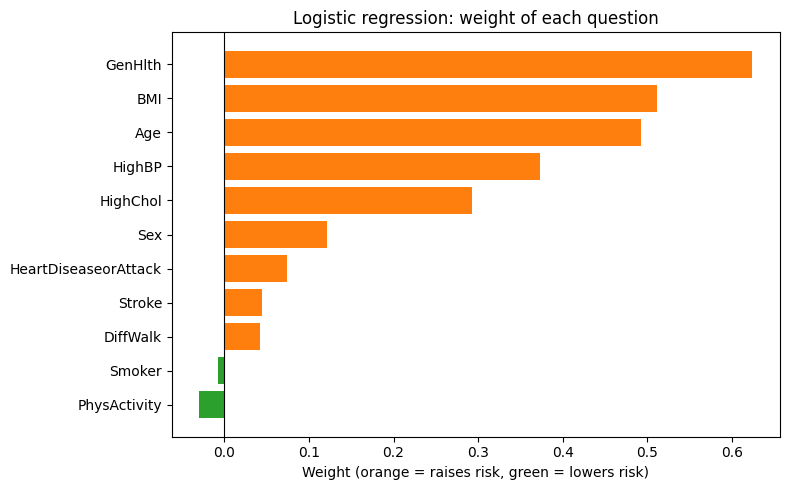

GenHlth                 0.624
BMI                     0.512
Age                     0.493
HighBP                  0.373
HighChol                0.293
Sex                     0.122
HeartDiseaseorAttack    0.074
Stroke                  0.045
DiffWalk                0.042
PhysActivity           -0.029
Smoker                 -0.008
dtype: float64


In [30]:
scaler = log_reg.named_steps['standardscaler']
lr_model = log_reg.named_steps['logisticregression']

weights = pd.Series(lr_model.coef_[0], index=FEATURES).sort_values()

plt.figure(figsize=(8, 5))
plt.barh(weights.index, weights.values,
         color=['tab:green' if w < 0 else 'tab:orange' for w in weights.values])
plt.axvline(0, color='black', linewidth=0.8)
plt.xlabel('Weight (orange = raises risk, green = lowers risk)')
plt.title('Logistic regression: weight of each question')
plt.tight_layout()
plt.show()

print(weights.sort_values(key=abs, ascending=False).round(3))

**Method 2: permutation importance (works for any model, including gradient boosting).** The idea is simple: take one question and **shuffle its answers randomly** between people, so it becomes useless. Then see how much the model's ROC-AUC drops. A big drop means the model relied heavily on that question.

We do this on the **validation** set, 5 times per question, and average.

In [31]:
from sklearn.inspection import permutation_importance

importance = {}
for name, model in [('Logistic regression', log_reg), ('Gradient boosting', gboost)]:
    result = permutation_importance(model, X_val, y_val, scoring='roc_auc',
                                    n_repeats=5, random_state=RANDOM_SEED)
    importance[name] = pd.Series(result.importances_mean, index=FEATURES)

importance = pd.DataFrame(importance).sort_values('Logistic regression', ascending=False)
print('Drop in validation ROC-AUC when each question is shuffled (bigger = more important):')
importance.round(4)

Drop in validation ROC-AUC when each question is shuffled (bigger = more important):


,Logistic regression,Gradient boosting
GenHlth,0.0654,0.0609
BMI,0.0367,0.0415
Age,0.0313,0.0409
HighBP,0.0215,0.0188
HighChol,0.0120,0.0119
Sex,0.0019,0.0028
HeartDiseaseorAttack,0.0013,0.0030
DiffWalk,0.0004,0.0027
Stroke,0.0003,0.0006
PhysActivity,0.0001,0.0002


**Two warnings when reading these:**
- **Important does not mean 'causes'.** For example, 'general health' is probably important partly because having diabetes *makes* people feel less healthy. Heart disease and stroke are often *results* of the same problems that cause diabetes. The model finds **patterns**, not causes.
- Questions that overlap share credit. For example, high blood pressure and heart disease often go together, so each one looks a bit less important than it would on its own.

### 12b. Per person: the top reasons for one customer

For logistic regression, a person's risk score is built by adding up one **push** per question:

> push = weight × (this person's answer − the average answer) ÷ spread

- A **positive push** means this answer makes this person **riskier than an average person**.
- A **negative push** means this answer makes them **less risky than average**.

The biggest positive pushes are the **top reasons** we show in the app, written in plain words. This is one of the main reasons we chose logistic regression: the explanation is *exact*, not a guess.

The app also uses our **age-group thresholds** from Section 11b, so the decision (Low risk / Higher risk) depends on the person's age group.

In [32]:
AGE_LABELS_SHORT = AGE_LABELS   # from Section 2b: {1: '18-24', ..., 13: '80+'}
HEALTH_WORDS = {1: 'excellent', 2: 'very good', 3: 'good', 4: 'fair', 5: 'poor'}

def describe(feature, value):
    """Turn one answer into plain words."""
    value = int(value)
    if feature == 'Age':                  return f'Age {AGE_LABELS_SHORT[value]}'
    if feature == 'Sex':                  return 'Male' if value == 1 else 'Female'
    if feature == 'BMI':                  return f'BMI of {value}'
    if feature == 'GenHlth':              return f"Rates general health as '{HEALTH_WORDS[value]}'"
    yes_no = {
        'HighBP':               ('Has high blood pressure', 'No high blood pressure'),
        'HighChol':             ('Has high cholesterol', 'No high cholesterol'),
        'PhysActivity':         ('Physically active in the past 30 days', 'No physical activity in the past 30 days'),
        'DiffWalk':             ('Difficulty walking or climbing stairs', 'No difficulty walking'),
        'Smoker':               ('Has smoked 100+ cigarettes in their life', 'Never a regular smoker'),
        'HeartDiseaseorAttack': ('History of heart disease or heart attack', 'No heart disease'),
        'Stroke':               ('History of stroke', 'No stroke'),
    }
    yes_text, no_text = yes_no[feature]
    return yes_text if value == 1 else no_text

def app_threshold(age_code):
    """The threshold the app uses for this person's age group (Section 11b)."""
    return group_thresholds[age_band(np.array([age_code]))[0]]

def explain_person(person):
    """person: one row (pandas Series) with the 11 answers.
    Returns the risk score, the decision, and the pushes for each question."""
    answers = person[FEATURES].values.astype(float)
    pushes = lr_model.coef_[0] * (answers - scaler.mean_) / scaler.scale_
    pushes = pd.Series(pushes, index=FEATURES).sort_values(ascending=False)
    score = log_reg.predict_proba(person[FEATURES].to_frame().T)[0, 1]
    threshold = app_threshold(int(person['Age']))
    decision = 'Higher risk: see a doctor for an HbA1c test' if score >= threshold else 'Low risk'
    return score, threshold, decision, pushes

# Only show pushes bigger than this, so tiny effects (like +0.01) are not shown as "reasons"
MIN_PUSH = 0.05

def print_explanation(person, true_label=None):
    score, threshold, decision, pushes = explain_person(person)
    print(f'Risk score {score:.2f} (threshold for this age group {threshold:.2f})  ->  {decision}')
    if true_label is not None:
        print(f"Real answer in the data: {'diabetes' if true_label == 1 else 'no diabetes'}")
    up = pushes[pushes > MIN_PUSH].head(3)
    down = pushes[pushes < -MIN_PUSH].sort_values().head(2)
    print('  Top reasons risk is HIGHER:')
    for f, p in up.items():
        print(f'    + {describe(f, person[f])}   (push {p:+.2f})')
    if len(up) == 0:
        print('    (none: no answer raises risk noticeably above average)')
    print('  Things that LOWER risk:')
    for f, p in down.items():
        print(f'    - {describe(f, person[f])}   (push {p:+.2f})')

print('Explanation helpers ready.')

Explanation helpers ready.


### 12c. Three real examples from the test set

We pick three different kinds of people: a correctly flagged diabetic, a correctly cleared non-diabetic, and a young diabetic who would have been **missed** with the normal threshold but is caught by the age-group threshold.

In [33]:
test_people = X_test.reset_index(drop=True)
app_flags = flags_with_age_thresholds(test_score_lr, test_age_band)   # the app's decisions

# Pick one example of each kind (the first match in the test set, so it's not cherry-picked)
example_1 = np.where((app_flags == 1) & (y_test_arr == 1))[0][0]                       # flagged, really diabetic
example_2 = np.where((app_flags == 0) & (y_test_arr == 0))[0][0]                       # cleared, really not diabetic
# young diabetic who is caught ONLY because of the age-group threshold (score below the normal 0.402)
example_3 = np.where((app_flags == 1) & (y_test_arr == 1) & (test_age_band == '18-39')
                     & (test_score_lr < THRESHOLD_LR))[0][0]

for title, i in [('Example 1: flagged, really has diabetes', example_1),
                 ('Example 2: low risk, really has no diabetes', example_2),
                 ('Example 3: young person (18-39), caught only thanks to the age-group threshold', example_3)]:
    print('=' * 70)
    print(title)
    print_explanation(test_people.iloc[i], y_test_arr[i])
    print()

Example 1: flagged, really has diabetes
Risk score 0.68 (threshold for this age group 0.40)  ->  Higher risk: see a doctor for an HbA1c test
Real answer in the data: diabetes
  Top reasons risk is HIGHER:
    + BMI of 36   (push +0.59)
    + Has high blood pressure   (push +0.43)
    + Age 65-69   (push +0.32)
  Things that LOWER risk:
    - No high cholesterol   (push -0.25)
    - Female   (push -0.11)

Example 2: low risk, really has no diabetes
Risk score 0.09 (threshold for this age group 0.28)  ->  Low risk
Real answer in the data: no diabetes
  Top reasons risk is HIGHER:
    (none: no answer raises risk noticeably above average)
  Things that LOWER risk:
    - Age 40-44   (push -0.49)
    - No high blood pressure   (push -0.32)

Example 3: young person (18-39), caught only thanks to the age-group threshold
Risk score 0.24 (threshold for this age group 0.11)  ->  Higher risk: see a doctor for an HbA1c test
Real answer in the data: diabetes
  Top reasons risk is HIGHER:
    + Has 

### What the explanations show

**Both models agree on the top 5 questions**, in almost the same order:

| Rank | Question | LR weight | ROC-AUC drop when shuffled (LR / GB) |
|---|---|---|---|
| 1 | General health (self-rated) | +0.62 | 0.065 / 0.061 |
| 2 | BMI | +0.51 | 0.037 / 0.042 |
| 3 | Age | +0.49 | 0.031 / 0.041 |
| 4 | High blood pressure | +0.37 | 0.022 / 0.019 |
| 5 | High cholesterol | +0.29 | 0.012 / 0.012 |

- These five do almost all the work. Sex, heart disease, difficulty walking and stroke add a little.
- **Surprise: physical activity and smoking add almost nothing** once the other questions are known. Shuffling them barely changes the score (a drop of 0.0001 or less), and their weights are close to zero.
  - Why? Their effect probably 'hides' inside other questions: inactive people tend to have a higher BMI and worse general health, so once we know those, activity tells us little extra.
  - Smoking's weight is even *slightly negative* (-0.008). That doesn't mean smoking protects against diabetes. It's a tiny effect, likely caused by overlap with heart disease and stroke, and it's too small to matter.
  - So we **never show** tiny pushes as reasons (we only show pushes bigger than 0.05). Otherwise the app could say something silly like 'risk is higher because you never smoked'.
  - Next step: we could drop these two questions to make the screening even faster, after checking that results stay the same.
- **General health is #1, but be careful:** people with (undiagnosed) diabetes may *feel* less healthy because of the disease. That makes it a strong warning sign, but not a cause.

**Per-person reasons work as intended.** For example, the flagged diabetic in Example 1 was flagged mainly because of a **BMI of 36**, **high blood pressure** and **age 65-69**. A pharmacist could explain that in one sentence. Example 3 shows the age-group threshold catching a young diabetic who would otherwise have been told 'low risk'.

## 13. Failure analysis: where does the tool go wrong, and why?

No screening tool is perfect. Knowing **how** it fails is as important as knowing how often. We look at the app's decisions (logistic regression with the age-group thresholds) on the **test set**.

There are two kinds of mistake:
- **Missed diabetics (false negatives):** told 'Low risk' but really have diabetes. The dangerous mistake.
- **False alarms (false positives):** told 'see a doctor' but don't have diabetes (as far as the survey knows). The cheap mistake.

### 13a. What do the mistakes have in common?
First we compare the **average answers** of people the tool got right vs. wrong.

In [34]:
missed = np.where((app_flags == 0) & (y_test_arr == 1))[0]        # diabetics told 'low risk'
caught = np.where((app_flags == 1) & (y_test_arr == 1))[0]        # diabetics flagged
false_alarms = np.where((app_flags == 1) & (y_test_arr == 0))[0]  # non-diabetics flagged
cleared = np.where((app_flags == 0) & (y_test_arr == 0))[0]       # non-diabetics told 'low risk'

print(f'Missed diabetics: {len(missed):,}   Caught diabetics: {len(caught):,}')
print(f'False alarms:     {len(false_alarms):,}   Correctly cleared: {len(cleared):,}\n')

averages = pd.DataFrame({
    'Missed diabetics': test_people.iloc[missed][FEATURES].mean(),
    'Caught diabetics': test_people.iloc[caught][FEATURES].mean(),
    'False alarms': test_people.iloc[false_alarms][FEATURES].mean(),
    'Correctly cleared': test_people.iloc[cleared][FEATURES].mean(),
})
print('Average answers in each group (yes/no questions = share answering yes; Age = age code 1-13; GenHlth 1 = excellent ... 5 = poor):')
averages.round(2)

Missed diabetics: 829   Caught diabetics: 6,240
False alarms:     20,066   Correctly cleared: 23,601

Average answers in each group (yes/no questions = share answering yes; Age = age code 1-13; GenHlth 1 = excellent ... 5 = poor):


,Missed diabetics,Caught diabetics,False alarms,Correctly cleared
Age,8.79,9.47,8.52,7.20
Sex,0.43,0.49,0.49,0.38
BMI,26.49,32.54,30.73,25.39
HighBP,0.23,0.82,0.67,0.13
HighChol,0.29,0.72,0.59,0.21
PhysActivity,0.83,0.60,0.68,0.85
GenHlth,2.16,3.44,3.05,1.82
DiffWalk,0.08,0.40,0.25,0.04
Smoker,0.44,0.53,0.50,0.38
HeartDiseaseorAttack,0.04,0.24,0.14,0.02


### 13b. Real examples the tool gets wrong

We pick specific people using clear rules (so we're not cherry-picking):
1. **The most confident miss:** the diabetic with the *lowest* risk score.
2. **A typical miss:** the missed diabetic in the *middle* of the missed group.
3. **The most confident false alarm:** the non-diabetic with the *highest* risk score.
4. **A typical false alarm:** the false alarm in the *middle* of the false-alarm group.

In [35]:
def middle_of(indices):
    """The person in the middle when the group is sorted by risk score."""
    return indices[np.argsort(test_score_lr[indices])[len(indices) // 2]]

failures = [
    ('Failure 1: most confident miss (diabetic with the lowest risk score)', missed[np.argmin(test_score_lr[missed])]),
    ('Failure 2: typical miss', middle_of(missed)),
    ('Failure 3: most confident false alarm (non-diabetic with the highest risk score)', false_alarms[np.argmax(test_score_lr[false_alarms])]),
    ('Failure 4: typical false alarm', middle_of(false_alarms)),
]

# Show their raw answers side by side
failure_rows = test_people.iloc[[i for _, i in failures]].copy()
failure_rows.index = [f'Failure {n}' for n in range(1, 5)]
failure_rows['Risk score'] = [round(test_score_lr[i], 3) for _, i in failures]
failure_rows['Real answer'] = ['diabetes' if y_test_arr[i] == 1 else 'no diabetes' for _, i in failures]
display(failure_rows)

for title, i in failures:
    print('=' * 75)
    print(title)
    print_explanation(test_people.iloc[i], y_test_arr[i])
    print()

,Age,Sex,BMI,HighBP,HighChol,PhysActivity,GenHlth,DiffWalk,Smoker,HeartDiseaseorAttack,Stroke,Risk score,Real answer
Failure 1,2,1,20,0,0,1,1,0,0,0,0,0.026,diabetes
Failure 2,10,0,24,0,0,1,3,1,1,0,0,0.266,diabetes
Failure 3,12,0,90,1,1,0,4,1,0,1,1,0.999,no diabetes
Failure 4,8,0,28,1,1,1,3,0,1,0,0,0.553,no diabetes


Failure 1: most confident miss (diabetic with the lowest risk score)
Risk score 0.03 (threshold for this age group 0.11)  ->  Low risk
Real answer in the data: diabetes
  Top reasons risk is HIGHER:
    + Male   (push +0.14)
  Things that LOWER risk:
    - Age 25-29   (push -0.98)
    - Rates general health as 'excellent'   (push -0.88)

Failure 2: typical miss
Risk score 0.27 (threshold for this age group 0.40)  ->  Low risk
Real answer in the data: diabetes
  Top reasons risk is HIGHER:
    + Age 65-69   (push +0.32)
    + Rates general health as 'good'   (push +0.29)
    + Difficulty walking or climbing stairs   (push +0.09)
  Things that LOWER risk:
    - BMI of 24   (push -0.34)
    - No high blood pressure   (push -0.32)

Failure 3: most confident false alarm (non-diabetic with the highest risk score)
Risk score 1.00 (threshold for this age group 0.40)  ->  Higher risk: see a doctor for an HbA1c test
Real answer in the data: no diabetes
  Top reasons risk is HIGHER:
    + BMI of 

### Why the tool fails: what we learned

**The big pattern (13a):** the tool fails when a person **doesn't look like a typical case**.

| Average answer | Missed diabetics | Correctly cleared | False alarms | Caught diabetics |
|---|---|---|---|---|
| BMI | 26.5 | 25.4 | 30.7 | 32.5 |
| High blood pressure | 23% | 13% | 67% | 82% |
| High cholesterol | 29% | 21% | 59% | 72% |
| General health (1 = excellent, 5 = poor) | 2.2 | 1.8 | 3.1 | 3.4 |

- **Missed diabetics look almost like healthy people:** normal-ish weight, mostly no high blood pressure, good self-rated health.
- **False alarms look almost like diabetics:** overweight, high blood pressure, high cholesterol, fair health.
- With only these 11 questions, there is no way to tell these people apart. A blood test is needed.

**The four real failures (13b):**

**Failure 1: most confident miss.** A **man aged 25-29, BMI 20, 'excellent' health**, no conditions, physically active. Risk score 0.03.
- Nothing in his answers suggests diabetes. Even the ADA checklist would give him only 1 point.
- **Possible reasons:** he may have **type 1 diabetes**, which affects young, lean people and isn't linked to lifestyle. Or his diabetes may be well controlled. A question-based tool can't catch cases like this.

**Failure 2: typical miss.** A **woman aged 65-69, BMI 24**, no high blood pressure or cholesterol, active, 'good' health. Risk score 0.27 (threshold 0.40).
- She's a **lean diabetic**. Age pushes her risk up, but her healthy weight and blood pressure pull it down.
- **Possible reasons:** (1) Some people develop type 2 diabetes without being overweight. (2) **After a diagnosis, people often change**: they lose weight, exercise more and take blood-pressure medicine. The survey records answers *after* diagnosis, so known diabetics can look healthier than they did before. This means our model may underrate risk for lean people.
- **UAE relevance:** people of South Asian origin, a large part of the UAE population, tend to develop type 2 diabetes at **lower BMI**. So lean diabetics like this may be **more common in the UAE** than in our US data. That's a key reason we need UAE data (see Limitations).

**Failure 3: most confident false alarm.** A **woman aged 75-79, BMI 90**, heart disease, stroke, high blood pressure and cholesterol, 'fair' health. Risk score 0.999.
- **A BMI of 90 is extreme**, possibly a data-entry mistake. Logistic regression treats BMI as a straight line, so this one answer gave a push of +4.80, more than everything else combined.
- **Lesson for the app:** we must **check inputs**. A wrong height or weight (e.g. centimetres typed as metres) could create a silly BMI and an automatic 'see a doctor'. The app will reject impossible heights and weights.
- Even ignoring BMI, she has many serious risk factors. Sending her for an HbA1c test is medically reasonable, and she could even have undiagnosed diabetes.

**Failure 4: typical false alarm.** A **woman aged 55-59, BMI 28, with high blood pressure and high cholesterol**, 'good' health. Risk score 0.55.
- She has the classic **metabolic risk factors** that often come before diabetes.
- **Possible reasons:** she may have **prediabetes** (remember from Section 1b that the 4,631 prediabetics are labelled 'no diabetes' in this data), or **undiagnosed diabetes**. The survey only knows about diabetes a doctor has diagnosed, and undiagnosed people are exactly who our tool is meant to find.
- So some 'false alarms' may not be false at all. An HbA1c test would tell.

**Bottom line:** our misses are mostly lean or young diabetics who don't fit the usual picture. Our false alarms are mostly people with real risk factors who may be prediabetic or undiagnosed. **Questions can narrow down who needs a blood test, but they can't replace it.**

## 14. Limitations: what this tool can't do (yet)

We want to be honest about the weaknesses, especially because this is a health tool.

### The data is from the wrong place and time
- **US adults in 2015, not UAE residents today.** The UAE population is very different: many nationalities (Emirati, South Asian, other Arab, Filipino and more), a younger, mostly expatriate workforce, and different diets and lifestyles.
- **The link between BMI and diabetes differs between populations.** People of South Asian and East Asian origin tend to develop type 2 diabetes at a **lower BMI**, which is why a WHO expert consultation suggested lower BMI action points for Asian populations, about 23 and 27.5 instead of 25 and 30 ([The Lancet, 2004](https://doi.org/10.1016/S0140-6736(03)15268-3)). Our model learned the US pattern, so it may **miss more lean diabetics in the UAE** (like Failure 2).
- **Type 2 diabetes may start younger in Gulf populations.** IDF data show diabetes is about twice as common among under-40s in the Middle East and North Africa as in Europe ([International Journal of Endocrinology, 2021](https://doi.org/10.1155/2021/6661346)). That's why we chose age-group thresholds, but the exact thresholds were tuned on US data.
- **2015 is over 10 years ago.** Obesity and diabetes rates have changed since.

### The answers are self-reported
- **The inputs** (weight, exercise, blood pressure history) come from people's own memory. People often under-report weight and over-report exercise.
- **The diabetes label** is also self-reported: 'Has a doctor ever told you that you have diabetes?'. So:
  - **Undiagnosed diabetics are labelled 'no diabetes'.** Some of our 'false alarms' may really be diabetic, which means our precision may look worse than it really is.
  - **Prediabetes is labelled 'no diabetes'** (Section 1b).
  - **Type 1 and type 2 are mixed together.** Type 1 can't be predicted from lifestyle questions (Failure 1).

### The survey is a snapshot after diagnosis
- People answered *after* they may already have been diagnosed and treated. Diagnosed diabetics may have lost weight, started exercising or taken blood-pressure medicine. So the data shows the **'after'** picture, while our tool is used on people **before** diagnosis.

### Missing questions
- **Family history** and **gestational diabetes** are two of the strongest known risk factors (they're on the ADA test), but they're not in the dataset. Family history is especially relevant in the UAE.

### Model limitations
- The output is a **risk score, not a probability** (because of the class weighting), so we never show it as a percentage.
- The age-group threshold for **18-39** was set from only about 260 young diabetics, so it's less precise.
- **Extreme or mistyped BMI values** (like BMI 90 in Failure 3) push the score up strongly. The app checks that height and weight are realistic.
- About **44-52% of customers get referred**. That's a lot of HbA1c tests. Fine for a screening tool, but a real rollout would need clinics to agree.
- **It has never been tested on real customers.** This is a prototype and is not medical advice.

### What data we'd need to make it work in the UAE
1. **A UAE study with blood tests:** a few thousand UAE residents of different nationalities, ages and sexes answer our questions **and** get an HbA1c test. The HbA1c result is the true answer, including people who don't know they're diabetic. This fixes the self-report and undiagnosed problems at once.
2. **Extra questions:** family history of diabetes, gestational diabetes, and nationality/ethnic background (to adjust for the BMI difference).
3. **Retrain and re-check:** retrain the model on the UAE data, re-choose the threshold, and re-run the fairness check by nationality group too, not just sex and age.
4. **A pilot in real pharmacies:** measure how many flagged customers actually get tested, and how many are diagnosed. That's the true test of whether the tool helps.

## 15. Save the model for the app

One nice thing about logistic regression: **the whole trained model is just a handful of numbers**:
- 11 **weights** (one per question) and 1 **intercept** (a starting value)
- the **average** and **spread** of each question in the training data (used for scaling)
- our **thresholds** (one per age group)

So instead of saving a complicated Python object, we save these numbers in a small, readable text file called **`model.json`**. The app reads this file and does the same maths:

> risk score = 1 / (1 + e^-(intercept + sum of weight × (answer − average) ÷ spread))

This also means the app doesn't depend on a particular version of scikit-learn, and anyone can open the file and see exactly what the model does.

In [36]:
import json

app_results = screening_metrics(y_test_arr, app_flags)   # app version (age-group thresholds) on the test set

model_file = {
    'about': 'Silent Diabetes screening model: logistic regression trained on CDC BRFSS 2015 (US adults). '
             'Prototype, not medical advice.',
    'features': FEATURES,
    'scaler_mean': [float(v) for v in scaler.mean_],
    'scaler_scale': [float(v) for v in scaler.scale_],
    'weights': [float(v) for v in lr_model.coef_[0]],
    'intercept': float(lr_model.intercept_[0]),
    'age_bands': AGE_BANDS,
    'age_group_thresholds': {band: float(t) for band, t in group_thresholds.items()},
    'single_threshold': float(THRESHOLD_LR),
    'min_push_to_show': MIN_PUSH,
    'test_results_app_version': {
        'recall': round(float(app_results['Recall']), 3),
        'precision': round(float(app_results['Precision']), 3),
        'false_negatives': int(app_results['False neg']),
        'false_positives': int(app_results['False pos']),
        'flagged_share': round(float(app_results['Flagged %']), 3),
        'test_people': int(len(y_test_arr)),
    },
}

with open('model.json', 'w') as f:
    json.dump(model_file, f, indent=2)

print('Saved model.json. Its full contents (copy this into the repo as model.json):\n')
print(json.dumps(model_file, indent=2))

Saved model.json. Its full contents (copy this into the repo as model.json):

{
  "about": "Silent Diabetes screening model: logistic regression trained on CDC BRFSS 2015 (US adults). Prototype, not medical advice.",
  "features": [
    "Age",
    "Sex",
    "BMI",
    "HighBP",
    "HighChol",
    "PhysActivity",
    "GenHlth",
    "DiffWalk",
    "Smoker",
    "HeartDiseaseorAttack",
    "Stroke"
  ],
  "scaler_mean": [
    8.039794228949859,
    0.44062729948491536,
    28.377759381898453,
    0.4295175023651845,
    0.4237425102491328,
    0.75746347103963,
    2.5122661095343215,
    0.16784925890886157,
    0.44199385052034057,
    0.09421975191842742,
    0.0400570272259014
  ],
  "scaler_scale": [
    3.049619830366716,
    0.4964623675904812,
    6.571381091707981,
    0.49500729037778646,
    0.49415057953714514,
    0.42861703311957355,
    1.0681015015690818,
    0.3737323710793695,
    0.4966238884936401,
    0.29213419907100474,
    0.19609299272468864
  ],
  "weights": [

### 15a. Check: does the saved file give exactly the same answers?

We reload `model.json`, redo the maths by hand (without scikit-learn), and compare with the real model on all 50,736 test people. The differences should be tiny (computer rounding only), and every decision should match.

In [37]:
with open('model.json') as f:
    saved = json.load(f)

answers = X_test[saved['features']].values.astype(float)
scaled = (answers - np.array(saved['scaler_mean'])) / np.array(saved['scaler_scale'])
log_odds = saved['intercept'] + scaled @ np.array(saved['weights'])
score_from_file = 1 / (1 + np.exp(-log_odds))

# Decisions using the saved age-group thresholds
band_of_person = age_band(X_test['Age'].values)
threshold_of_person = np.array([saved['age_group_thresholds'][b] for b in band_of_person])
flags_from_file = (score_from_file >= threshold_of_person).astype(int)

print(f'Biggest difference in risk score: {np.abs(score_from_file - test_score_lr).max():.8f}')
print(f'Decisions that differ: {(flags_from_file != app_flags).sum()} out of {len(app_flags):,}')

Biggest difference in risk score: 0.00000000
Decisions that differ: 0 out of 50,736


## 16. The pharmacist app

The app lives in **`app.py`** in our GitHub repo. It:
- asks the questions in friendly wording, in **English or Arabic**
- calculates **BMI from height and weight**, and rejects unrealistic values (lesson from Failure 3)
- shows **Low risk** (green) or **Higher risk: please see a doctor for an HbA1c blood test** (orange)
- shows the **top reasons** in plain words, never a percentage (the score isn't a real probability)
- always shows: *This project is a prototype and is not medical advice.*

It uses the `model.json` file we just saved in Section 15, and the **age-group thresholds** from Section 11b.

### 16a. Check: does the app give the same decisions as the notebook?
We download `app.py`, run its `predict` function on every test person, and compare with the notebook's decisions.

In [38]:
# Download app.py from our GitHub repo (model.json was saved in this session in Section 15)
!wget -q -O app.py https://raw.githubusercontent.com/MrSiwan0909/silent-diabetes/main/app.py

import importlib
import app
importlib.reload(app)   # make sure we use the freshly downloaded version

# Run the app's own predict() on every test person
app_decisions = np.array([
    int(app.predict(dict(zip(FEATURES, row)))[1])
    for row in X_test[FEATURES].values.astype(float)
])
print(f'App decisions that differ from the notebook: {(app_decisions != app_flags).sum()} out of {len(app_flags):,}')

App decisions that differ from the notebook: 0 out of 50,736


In [39]:
from IPython.display import HTML

# Try the app's result screen for two made-up customers (no buttons needed)
# Order: language, age, sex (1 = male), height cm, weight kg, high BP, high cholesterol,
#        physically active, general health (1-5), difficulty walking, smoker, heart disease, stroke
display(HTML(app.assess('English', 58, 1, 172, 96, 1, 1, 0, 4, 0, 1, 0, 0)))
display(HTML(app.assess('العربية', 29, 0, 160, 55, 0, 0, 1, 2, 0, 0, 0, 0)))
# A typing mistake: height typed in metres instead of cm, so the app should refuse
display(HTML(app.assess('English', 45, 0, 1.6, 70, 0, 0, 1, 3, 0, 0, 0, 0)))

### 16b. Launch the app (for the demo)

Run the next cell. After a few seconds it prints two links:
- a **local URL**, which only works inside Colab
- a **public URL** ending in `.gradio.live`. **Open this one.** It works on any phone or laptop, so you can demo it to judges. It stops working when this Colab session stops (and after at most a week), so re-run this cell before your demo.

The app keeps running until you stop the cell (■ button) or close Colab.

In [40]:
app.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://78bba2742e1eaa0582.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


# 17. Extra analyses (added after the main results)

Everything above this point is our **main project**. The test set was used once, in Section 10, for the main results.

The analyses below were added **afterwards** to answer questions a judge might ask. To keep them honest, we follow one rule:

> **Every choice (thresholds, features, settings) is made on the VALIDATION set only. Then we report the test set once.**

That way, none of these extra results is 'tuned' to the test set. **None of them changes the app**, unless we say so explicitly.

## 17a. Is it the AI, or just more questions?

In Section 8, our model beat the ADA checklist. But our model uses **11 questions**, while our ADA version uses only **5**. So where does the gain come from?

- **(a) Better weights:** the computer learns better 'points' for each answer than the ADA committee chose, and it uses exact BMI and age instead of bands.
- **(b) More questions:** general health, cholesterol, heart disease, stroke, difficulty walking and smoking add information the ADA checklist doesn't have.

**The test:** we train a logistic regression on **only the same 5 questions the ADA score uses** (Age, Sex, HighBP, PhysActivity, BMI). Then we compare three methods:
1. ADA score (fixed points chosen by experts)
2. Logistic regression with the **same 5 questions**, which shows the gain from (a) only
3. Logistic regression with **all 11 questions** (our main model), which shows (a) + (b)

As in Section 8, we compare fairly at the **same workload** (same % of people flagged as the ADA checklist) and at the **same recall** (same % of diabetics caught).

In [41]:
ADA_QUESTIONS = ['Age', 'Sex', 'HighBP', 'PhysActivity', 'BMI']

# Same recipe as our main model (Section 7), but only the 5 ADA questions
log_reg_5 = make_pipeline(
    StandardScaler(),
    LogisticRegression(class_weight='balanced', max_iter=1000)
)
log_reg_5.fit(X_train[ADA_QUESTIONS], y_train)      # learn from the TRAINING set only
val_score_5 = log_reg_5.predict_proba(X_val[ADA_QUESTIONS])[:, 1]

# The weights it learned (scaled, so they can be compared with each other)
weights_5 = pd.Series(log_reg_5.named_steps['logisticregression'].coef_[0], index=ADA_QUESTIONS)
print('Weights learned from the same 5 ADA questions (bigger = matters more):')
print(weights_5.sort_values(ascending=False).round(3))

Weights learned from the same 5 ADA questions (bigger = matters more):
BMI             0.610
Age             0.561
HighBP          0.551
Sex             0.100
PhysActivity   -0.172
dtype: float64


In [42]:
# ---- Step 1: compare on the VALIDATION set (same method as Section 8) ----
rows = {'ADA score >= 5 (5 questions, expert points)': {
    'ROC-AUC': roc_auc_score(y_val_arr, val_ada),
    'Recall at ADA workload': ada_recall,
    'Flagged % needed for ADA recall': ada_flag_share,
}}
for name, score in [('Logistic regression, same 5 questions', val_score_5),
                    ('Logistic regression, all 11 questions', val_score_lr)]:
    recall, _ = recall_when_flagging(y_val_arr, score, ada_flag_share)
    share, _ = flagged_share_for_recall(y_val_arr, score, ada_recall)
    rows[name] = {'ROC-AUC': roc_auc_score(y_val_arr, score),
                  'Recall at ADA workload': recall,
                  'Flagged % needed for ADA recall': share}

print(f'VALIDATION set. ADA workload = {ada_flag_share:.1%} flagged, ADA recall = {ada_recall:.1%}\n')
pd.DataFrame(rows).T.round(3)

VALIDATION set. ADA workload = 47.4% flagged, ADA recall = 80.7%



,ROC-AUC,Recall at ADA workload,Flagged % needed for ADA recall
"ADA score >= 5 (5 questions, expert points)",0.758,0.807,0.474
"Logistic regression, same 5 questions",0.775,0.830,0.447
"Logistic regression, all 11 questions",0.817,0.876,0.388


### Test set (reported once)

We now **fix the thresholds on the validation set**, then apply them unchanged to the test set:
- **'Same workload' threshold:** the score that flags the same share of validation people as the ADA checklist (47.4%).
- **'Same recall' threshold:** the score that catches the same share of validation diabetics as the ADA checklist (80.7%).

Then we count how many of the test diabetics each method misses, and how many healthy people it flags.

In [43]:
# ---- Step 2: choose thresholds on VALIDATION ----
thresholds_b2 = {
    '5 questions': {'workload': np.quantile(val_score_5, 1 - ada_flag_share),
                    'recall': threshold_for_recall(y_val_arr, val_score_5, ada_recall)},
    '11 questions': {'workload': np.quantile(val_score_lr, 1 - ada_flag_share),
                     'recall': threshold_for_recall(y_val_arr, val_score_lr, ada_recall)},
}

# ---- Step 3: apply them once to the TEST set ----
test_score_5 = log_reg_5.predict_proba(X_test[ADA_QUESTIONS])[:, 1]
test_scores_b2 = {'5 questions': test_score_5, '11 questions': test_score_lr}

b2_rows = {'ADA score >= 5': screening_metrics(y_test_arr, (test_ada >= 5).astype(int), test_ada)}
for match in ['workload', 'recall']:
    for n_questions in ['5 questions', '11 questions']:
        score = test_scores_b2[n_questions]
        flags = (score >= thresholds_b2[n_questions][match]).astype(int)
        b2_rows[f'LR, {n_questions}, same {match} as ADA'] = screening_metrics(y_test_arr, flags, score)

b2_table = pd.DataFrame(b2_rows).T
b2_table[['False neg', 'False pos']] = b2_table[['False neg', 'False pos']].astype(int)
b2_table = b2_table[['Recall', 'False neg', 'False pos', 'Flagged %', 'ROC-AUC']]
print(f'TEST set: {len(y_test_arr):,} people, {int(y_test_arr.sum()):,} diabetics\n')
display(b2_table.round(3))

# ---- How much of the gain comes from better weights alone? (same-workload comparison) ----
missed_ada = b2_table.loc['ADA score >= 5', 'False neg']
missed_5 = b2_table.loc['LR, 5 questions, same workload as ADA', 'False neg']
missed_11 = b2_table.loc['LR, 11 questions, same workload as ADA', 'False neg']
print(f'At the ADA workload, missed diabetics: ADA {missed_ada:,} -> 5-question LR {missed_5:,} -> 11-question LR {missed_11:,}')
if missed_ada > missed_11:
    share_weights = (missed_ada - missed_5) / (missed_ada - missed_11)
    print(f'Better weights (same 5 questions) explain {share_weights:.0%} of the reduction in missed diabetics;')
    print(f'the extra 6 questions explain the other {1 - share_weights:.0%}.')

TEST set: 50,736 people, 7,069 diabetics



,Recall,False neg,False pos,Flagged %,ROC-AUC
ADA score >= 5,0.812,1331,18450,0.477,0.757
"LR, 5 questions, same workload as ADA",0.829,1209,18308,0.476,0.774
"LR, 11 questions, same workload as ADA",0.873,895,17880,0.474,0.815
"LR, 5 questions, same recall as ADA",0.809,1349,17112,0.450,0.774
"LR, 11 questions, same recall as ADA",0.805,1378,14039,0.389,0.815


At the ADA workload, missed diabetics: ADA 1,331 -> 5-question LR 1,209 -> 11-question LR 895
Better weights (same 5 questions) explain 28% of the reduction in missed diabetics;
the extra 6 questions explain the other 72%.


### What we found: mostly the extra questions, but the AI's weights help too

**Test set, at the same workload as the ADA checklist (about 47.5% of people flagged):**

| Method | ROC-AUC | Diabetics missed | False alarms |
|---|---|---|---|
| ADA score (5 questions, expert points) | 0.757 | 1,331 | 18,450 |
| Logistic regression, **same 5 questions** | 0.774 | 1,209 | 18,308 |
| Logistic regression, **all 11 questions** | 0.815 | 895 | 17,880 |

- With the **same 5 questions**, learned weights alone miss **122 fewer diabetics** than the ADA points (1,331 → 1,209).
- Adding the **other 6 questions** misses **314 fewer** on top of that (1,209 → 895).
- So **about 28% of the improvement comes from better weights, and about 72% from the extra questions.**

**At the same recall as the ADA checklist (about 81% of diabetics caught):** the 5-question model flags 45.0% of people (vs 47.7% for ADA), and the 11-question model flags 38.9%. That's **1,338** and **4,411 fewer false alarms** than the ADA checklist. (On the test set, both models caught slightly fewer diabetics than the ADA here, 80.9% and 80.5% vs 81.2%, because their thresholds were set on the validation set. That small gap is normal and honest.)

**What the learned weights say:** BMI (0.61), age (0.56) and high blood pressure (0.55) matter about equally, sex matters little (0.10), and being active lowers risk (-0.17). The ADA checklist gives up to 3 points for age and BMI but only 1 for blood pressure. Our data suggests **high blood pressure deserves more weight** than the ADA gives it.

**In plain words:** the AI does make the ADA's own questions work a bit better, but **most of our advantage comes from asking smarter questions**, especially general health (Section 12). This is an honest correction to any claim that 'the AI alone' beats the checklist.

## 17b. UAE stress test (a simulation, not real UAE data)

**Why:** a large part of the UAE population is of South Asian origin (and many residents are East Asian). People of Asian origin tend to develop type 2 diabetes at a **lower BMI** than people of European origin. That's why a WHO expert consultation suggested lower BMI 'action points' for Asian populations: about **23** and **27.5** instead of the usual **25** and **30** ([WHO expert consultation, *The Lancet*, 2004](https://doi.org/10.1016/S0140-6736(03)15268-3)).

Our model learned the US pattern, where diabetics tend to be heavier. In Failure 2 (Section 13), we already saw it miss a lean diabetic. **How badly could this hurt in the UAE?**

**The simulation:** we pretend the test set is a population where diabetics are leaner. We **lower the BMI of every diabetic by 2.5 units** (the gap between 30 and 27.5 above) and leave everyone else unchanged. Then we measure how much the app's recall drops.

**One simple fix:** if a customer says they are of South Asian or East Asian background, the app adds a number to their BMI before using the model. This 'translates' an Asian BMI into the US scale the model learned. We **choose that number on the validation set** (with the same simulation), then test it once.

**Important limits, so we don't over-claim:**
- This is a **thought experiment, not real UAE data**. Real differences between populations involve more than BMI (diet, genes, waist size, family history).
- In the simulation, we *know* the BMI gap is exactly 2.5, so the fix is partly guaranteed to work. The real gap would have to be measured.
- Only **real UAE data with blood tests** (HbA1c) can tell us how well the tool works in the UAE, and what the right adjustment is.

In [44]:
BMI_SHIFT = 2.5   # simulated: diabetics are this much leaner (WHO: 30 -> 27.5)

def simulate_leaner_diabetics(X, y, shift=BMI_SHIFT):
    """Copy of X where every diabetic's BMI is lowered by `shift`. Everyone else is unchanged."""
    X_sim = X.copy()
    X_sim['BMI'] = X_sim['BMI'].astype(float)
    X_sim.loc[np.asarray(y) == 1, 'BMI'] -= shift
    return X_sim

def app_flags_for(X, bmi_adjustment=0.0):
    """The app's decisions (age-group thresholds), after adding `bmi_adjustment` to everyone's BMI."""
    X_adj = X.copy()
    X_adj['BMI'] = X_adj['BMI'].astype(float) + bmi_adjustment
    scores = log_reg.predict_proba(X_adj[FEATURES])[:, 1]
    return flags_with_age_thresholds(scores, age_band(X_adj['Age'].values))

# ---- VALIDATION: how much does recall drop, and which adjustment brings it back? ----
val_recall_normal = screening_metrics(y_val_arr, app_flags_for(X_val))['Recall']
X_val_sim = simulate_leaner_diabetics(X_val, y_val_arr)

fix_rows = {}
for adjustment in [0.0, 0.5, 1.0, 1.5, 2.0, 2.5, 3.0]:
    m = screening_metrics(y_val_arr, app_flags_for(X_val_sim, adjustment))
    fix_rows[adjustment] = {'Recall': m['Recall'], 'False neg': int(m['False neg']),
                                      'False pos': int(m['False pos']), 'Flagged %': m['Flagged %']}
fix_table = pd.DataFrame(fix_rows).T
fix_table.index.name = 'BMI added'
fix_table[['False neg', 'False pos']] = fix_table[['False neg', 'False pos']].astype(int)

print(f'VALIDATION, normal data: app recall {val_recall_normal:.3f}')
print('VALIDATION, simulated leaner diabetics, adding different amounts to BMI (in the simulation, everyone counts as South/East Asian):')
display(fix_table.round(3))

# Choose the SMALLEST adjustment that brings recall back to the normal level (fewest extra false alarms)
good_enough = fix_table[fix_table['Recall'] >= val_recall_normal]
CHOSEN_BMI_ADJUSTMENT = float(good_enough.index[0]) if len(good_enough) else 3.0
print(f'Chosen on validation: add {CHOSEN_BMI_ADJUSTMENT} to BMI for South Asian / East Asian customers')

VALIDATION, normal data: app recall 0.886
VALIDATION, simulated leaner diabetics, adding different amounts to BMI (in the simulation, everyone counts as South/East Asian):


,Recall,False neg,False pos,Flagged %
BMI added,,,,
0.0,0.845,1094,20102,0.514
0.5,0.853,1040,20570,0.524
1.0,0.860,991,21066,0.535
1.5,0.870,917,21545,0.546
2.0,0.878,865,22100,0.558
2.5,0.886,809,22628,0.569
3.0,0.891,774,23192,0.581


Chosen on validation: add 2.5 to BMI for South Asian / East Asian customers


In [45]:
# ---- TEST (reported once): normal data vs simulation vs simulation + fix ----
X_test_sim = simulate_leaner_diabetics(X_test, y_test_arr)

b3_rows = {
    'Normal test data (app as it is)': screening_metrics(y_test_arr, app_flags_for(X_test)),
    'Simulated leaner diabetics, no fix': screening_metrics(y_test_arr, app_flags_for(X_test_sim)),
    f'Simulated, with fix (+{CHOSEN_BMI_ADJUSTMENT} BMI)': screening_metrics(
        y_test_arr, app_flags_for(X_test_sim, CHOSEN_BMI_ADJUSTMENT)),
}
b3_table = pd.DataFrame(b3_rows).T
b3_table[['False neg', 'False pos']] = b3_table[['False neg', 'False pos']].astype(int)
b3_table = b3_table[['Recall', 'False neg', 'False pos', 'Flagged %', 'Precision']]
print(f'TEST set: {len(y_test_arr):,} people, {int(y_test_arr.sum()):,} diabetics\n')
display(b3_table.round(3))

normal, sim, fixed = b3_table.index
print(f"Recall drop from the simulation: {b3_table.loc[normal, 'Recall']:.1%} -> {b3_table.loc[sim, 'Recall']:.1%}  "
      f"({b3_table.loc[sim, 'False neg'] - b3_table.loc[normal, 'False neg']:+,} missed diabetics)")
print(f"The fix: recall back to {b3_table.loc[fixed, 'Recall']:.1%}  "
      f"({b3_table.loc[fixed, 'False neg'] - b3_table.loc[sim, 'False neg']:+,} missed diabetics vs no fix)")
print(f"Cost of the fix: {b3_table.loc[fixed, 'False pos'] - b3_table.loc[sim, 'False pos']:+,} false alarms vs no fix")

TEST set: 50,736 people, 7,069 diabetics



,Recall,False neg,False pos,Flagged %,Precision
Normal test data (app as it is),0.883,829,20066,0.518,0.237
"Simulated leaner diabetics, no fix",0.840,1129,20066,0.513,0.228
"Simulated, with fix (+2.5 BMI)",0.883,829,22674,0.570,0.216


Recall drop from the simulation: 88.3% -> 84.0%  (+300 missed diabetics)
The fix: recall back to 88.3%  (-300 missed diabetics vs no fix)
Cost of the fix: +2,608 false alarms vs no fix


### What the simulation shows

**Built-in check:** the 'normal test data' row matches our main app results exactly (recall 88.3%, 829 missed, 20,066 false alarms), so the simulation code uses the real app logic.

**Test set (simulation, reported once):**

| | Recall | Diabetics missed | False alarms | % flagged |
|---|---|---|---|---|
| Normal test data (app as it is) | 88.3% | 829 | 20,066 | 51.8% |
| Simulated leaner diabetics, **no fix** | **84.0%** | **1,129** | 20,066 | 51.3% |
| Simulated, **with fix** (+2.5 BMI) | 88.3% | 829 | 22,674 | 57.0% |

- **The risk is real:** if diabetics in the UAE are 2.5 BMI units leaner than in the US data, the app would **miss 300 more diabetics** out of 7,069, and recall would drop from 88.3% to 84.0%.
- **The fix works, but it isn't free:** adding 2.5 to BMI for South/East Asian customers brings recall back to 88.3%, but adds **2,608 false alarms** (about 9 extra blood tests per extra diabetic caught), and raises the share flagged from 51.3% to 57.0%.
- The adjustment (+2.5) was chosen on the validation set as the smallest value that restored recall. It also matches the WHO gap between 30 and 27.5.

**Why we must not over-claim:**
- We **built** the problem (diabetics exactly 2.5 BMI leaner), so the +2.5 fix is almost guaranteed to undo it. This shows the *size* of the risk and that a simple fix is possible, not that the fix is right for real UAE customers.
- In reality, Asian non-diabetics may also have different BMIs, and differences involve waist size, diet, genes and family history, not just BMI.
- **Only real UAE data with HbA1c blood tests can measure the true gap.** That's the top item in our next steps.

**We did not change the app.** Adding this fix would need a new 'background' question, which should only be added once real data confirms the right adjustment.

## 17c. Do we need all 11 questions? (a 9-question version)

In Section 12, **physical activity** and **smoking** added almost nothing once the other questions were known: shuffling them barely changed the score, and their weights were close to zero.

If we can drop them without losing accuracy, the pharmacist's screening gets **faster** (2 fewer questions per customer) and simpler.

**The test:**
1. Retrain the same logistic regression **without** physical activity and smoking (9 questions).
2. On the **validation** set, choose its thresholds exactly as we did for the main model: one threshold that catches 85% of diabetics, plus the age-group thresholds for the app version.
3. Compare with the 11-question model on validation, then report the **test** set once.

**The app is not changed** by this analysis.

In [46]:
FEATURES_9 = [f for f in FEATURES if f not in ['PhysActivity', 'Smoker']]
print('9 questions:', FEATURES_9)

log_reg_9 = make_pipeline(StandardScaler(), LogisticRegression(class_weight='balanced', max_iter=1000))
log_reg_9.fit(X_train[FEATURES_9], y_train)                 # TRAINING set only
val_score_9 = log_reg_9.predict_proba(X_val[FEATURES_9])[:, 1]

# ---- Choose thresholds on VALIDATION, the same way as for the main model (Sections 9 and 11a) ----
threshold_9 = threshold_for_recall(y_val_arr, val_score_9, TARGET_RECALL)
group_thresholds_9 = {}
for band in AGE_BANDS:
    in_band = val_age_band == band
    group_thresholds_9[band] = min(threshold_9, threshold_for_recall(y_val_arr[in_band], val_score_9[in_band], TARGET_RECALL))

def flags_with_thresholds(risk_score, bands, thresholds_by_band):
    """Flag each person using the threshold for their age group."""
    return (risk_score >= np.array([thresholds_by_band[b] for b in bands])).astype(int)

print(f'Single threshold: 11 questions {THRESHOLD_LR:.3f}, 9 questions {threshold_9:.3f}')
print('Age-group thresholds (9 questions):', {b: round(float(t), 3) for b, t in group_thresholds_9.items()})

# ---- Compare on VALIDATION ----
val_rows = {
    '11 questions, single threshold': screening_metrics(y_val_arr, (val_score_lr >= THRESHOLD_LR).astype(int), val_score_lr),
    '9 questions, single threshold': screening_metrics(y_val_arr, (val_score_9 >= threshold_9).astype(int), val_score_9),
    '11 questions, app version (age thresholds)': screening_metrics(
        y_val_arr, flags_with_thresholds(val_score_lr, val_age_band, group_thresholds), val_score_lr),
    '9 questions, app version (age thresholds)': screening_metrics(
        y_val_arr, flags_with_thresholds(val_score_9, val_age_band, group_thresholds_9), val_score_9),
}
b4_val = pd.DataFrame(val_rows).T
b4_val[['False neg', 'False pos']] = b4_val[['False neg', 'False pos']].astype(int)
print('\nVALIDATION set:')
b4_val[['Recall', 'False neg', 'False pos', 'Flagged %', 'ROC-AUC']].round(3)

9 questions: ['Age', 'Sex', 'BMI', 'HighBP', 'HighChol', 'GenHlth', 'DiffWalk', 'HeartDiseaseorAttack', 'Stroke']
Single threshold: 11 questions 0.402, 9 questions 0.401
Age-group thresholds (9 questions): {'18-39': 0.111, '40-49': 0.285, '50-59': 0.355, '60-69': 0.401, '70+': 0.401}

VALIDATION set:


,Recall,False neg,False pos,Flagged %,ROC-AUC
"11 questions, single threshold",0.850,1060,16117,0.436,0.817
"9 questions, single threshold",0.850,1060,16119,0.436,0.817
"11 questions, app version (age thresholds)",0.886,809,20102,0.520,0.817
"9 questions, app version (age thresholds)",0.885,811,20061,0.519,0.817


In [47]:
# ---- TEST set, reported once (thresholds fixed on validation above) ----
test_score_9 = log_reg_9.predict_proba(X_test[FEATURES_9])[:, 1]

test_rows = {
    '11 questions, single threshold': screening_metrics(y_test_arr, (test_score_lr >= THRESHOLD_LR).astype(int), test_score_lr),
    '9 questions, single threshold': screening_metrics(y_test_arr, (test_score_9 >= threshold_9).astype(int), test_score_9),
    '11 questions, app version (age thresholds)': screening_metrics(
        y_test_arr, flags_with_thresholds(test_score_lr, test_age_band, group_thresholds), test_score_lr),
    '9 questions, app version (age thresholds)': screening_metrics(
        y_test_arr, flags_with_thresholds(test_score_9, test_age_band, group_thresholds_9), test_score_9),
}
b4_test = pd.DataFrame(test_rows).T
b4_test[['False neg', 'False pos']] = b4_test[['False neg', 'False pos']].astype(int)
b4_test = b4_test[['Recall', 'False neg', 'False pos', 'Flagged %', 'ROC-AUC']]
print(f'TEST set: {len(y_test_arr):,} people, {int(y_test_arr.sum()):,} diabetics\n')
display(b4_test.round(3))

for version in ['single threshold', 'app version (age thresholds)']:
    a, b = b4_test.loc[f'11 questions, {version}'], b4_test.loc[f'9 questions, {version}']
    print(f"{version}: 9 questions vs 11 -> missed {int(b['False neg'] - a['False neg']):+,}, "
          f"false alarms {int(b['False pos'] - a['False pos']):+,}, ROC-AUC {b['ROC-AUC'] - a['ROC-AUC']:+.4f}")

TEST set: 50,736 people, 7,069 diabetics



,Recall,False neg,False pos,Flagged %,ROC-AUC
"11 questions, single threshold",0.849,1065,16145,0.437,0.815
"9 questions, single threshold",0.848,1071,16169,0.437,0.815
"11 questions, app version (age thresholds)",0.883,829,20066,0.518,0.815
"9 questions, app version (age thresholds)",0.882,836,20071,0.518,0.815


single threshold: 9 questions vs 11 -> missed +6, false alarms +24, ROC-AUC -0.0001
app version (age thresholds): 9 questions vs 11 -> missed +7, false alarms +5, ROC-AUC -0.0001


### What we found: 9 questions work just as well

**Built-in check:** the 11-question rows match our main results exactly (single threshold: 1,065 missed, 16,145 false alarms; app version: 829 missed, 20,066 false alarms).

**Test set (reported once):**

| | Recall | Diabetics missed | False alarms | % flagged | ROC-AUC |
|---|---|---|---|---|---|
| 11 questions, single threshold | 84.9% | 1,065 | 16,145 | 43.7% | 0.815 |
| 9 questions, single threshold | 84.8% | 1,071 | 16,169 | 43.7% | 0.815 |
| 11 questions, app version | 88.3% | 829 | 20,066 | 51.8% | 0.815 |
| 9 questions, app version | 88.2% | 836 | 20,071 | 51.8% | 0.815 |

- Dropping physical activity and smoking changes almost nothing: **6-7 more missed diabetics out of 7,069** (about 0.1%), 5-24 more false alarms out of about 43,700 non-diabetics, and ROC-AUC down by only 0.0001.
- The thresholds chosen on validation are almost the same too (0.401 vs 0.402).
- **Meaning for the pharmacist:** the screening could be **2 questions shorter (9 instead of 11)** with practically the same results. That's faster for busy pharmacies and mall booths.

**Why it works:** the information in these two questions is already captured by others. Inactive people tend to have a higher BMI and rate their health lower, and smoking overlaps with heart disease and stroke.

**Should we still ask them?** They're cheap to ask, and they're useful **health advice** topics even if they don't change the score. They might also matter more in the UAE than in the US data. **We have not changed the app.** Switching to 9 questions is an easy option once UAE data confirms these results.